
TRAINING CENTRALIZED DQN - RANDOM SEED 42

Episode 0 demand sample:
A: [3.0, 3.0, 0, 6.0, 3.0, 3.0, 6.0, 9.0, 6.0, 0, 0, 3.0, 3.0, 6.0, 6.0, 9.0, 6.0, 3.0, 0, 0, 0]
B: [2.0, 2.0, 2.0, 4.0, 4.0, 2.0, 4.0, 4.0, 4.0, 2.0, 0, 2.0, 2.0, 4.0, 4.0, 4.0, 4.0, 4.0, 2.0, 0, 0]
C: [0, 0, 0, 0, 4.0, 4.0, 8.0, 4.0, 4.0, 4.0, 0, 0, 4.0, 4.0, 4.0, 4.0, 8.0, 4.0, 4.0, 0, 0]

Episode 0 demand sample:
A: [3.0, 3.0, 0, 6.0, 3.0, 3.0, 6.0, 9.0, 6.0, 0, 0, 3.0, 3.0, 6.0, 6.0, 9.0, 6.0, 3.0, 0, 0, 0]
B: [2.0, 2.0, 2.0, 4.0, 4.0, 2.0, 4.0, 4.0, 4.0, 2.0, 0, 2.0, 2.0, 4.0, 4.0, 4.0, 4.0, 4.0, 2.0, 0, 0]
C: [0, 0, 0, 0, 4.0, 4.0, 8.0, 4.0, 4.0, 4.0, 0, 0, 4.0, 4.0, 4.0, 4.0, 8.0, 4.0, 4.0, 0, 0]
Episode   500 | Reward:  -208447.7 | Epsilon: 0.779
Episode  1000 | Reward:  -368764.0 | Epsilon: 0.606
Episode  1500 | Reward:  -418203.6 | Epsilon: 0.472
Episode  2000 | Reward:  -208643.3 | Epsilon: 0.368
Episode  2500 | Reward:  -142905.4 | Epsilon: 0.286
Episode  3000 | Reward:   -84122.7 | Epsilon: 0.223
Episode

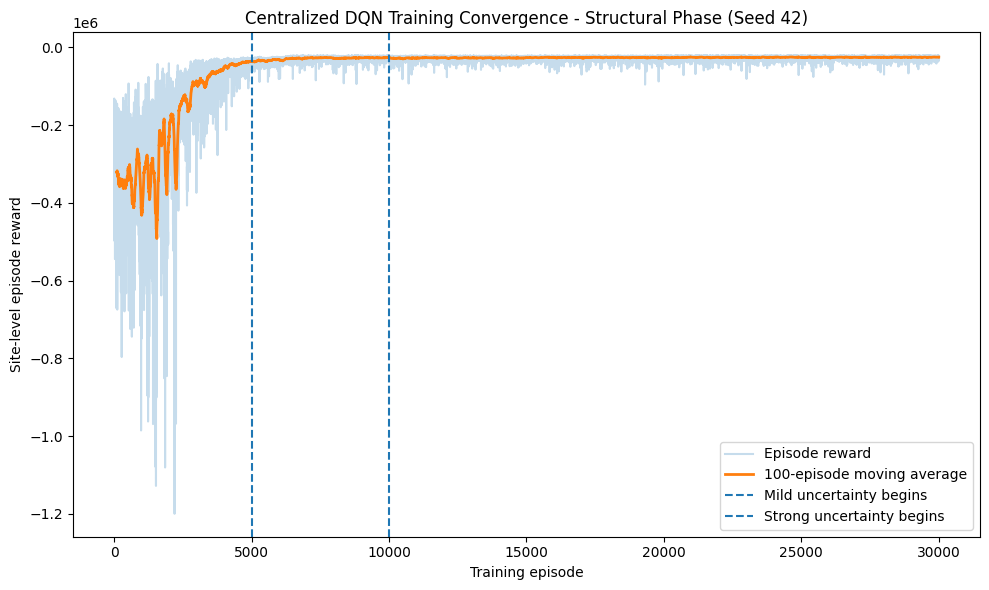


=== Greedy centralised DQN evaluation (episode=12000) ===

Day 1
Joint truck allocation: A=2, B=2, C=0 (Total=4/4)
Product A -> Allocated Trucks: 2, Allocated Qty: 6, Delivery Today: 3, Backlog Today: 0, Planned Demand Today: 3, Planned Demand Tomorrow: 3, Realised Demand Today: 3.0, Actual Demand incl. Backlog: 3.0, Ending Inv: 0, Unmet: 0, Product Cost: 604.5
Product B -> Allocated Trucks: 2, Allocated Qty: 4, Delivery Today: 2, Backlog Today: 0, Planned Demand Today: 2, Planned Demand Tomorrow: 2, Realised Demand Today: 2.1, Actual Demand incl. Backlog: 2.1, Ending Inv: 0, Unmet: 0.10000000000000009, Product Cost: 534.7
Product C -> Allocated Trucks: 0, Allocated Qty: 0, Delivery Today: 0, Backlog Today: 0, Planned Demand Today: 0, Planned Demand Tomorrow: 0, Realised Demand Today: 0, Actual Demand incl. Backlog: 0, Ending Inv: 0, Unmet: 0, Product Cost: 0.0
Shared Storage Used: 0.0 / 20.0 m² | Excess: 0.0 m² | Excess Cost: £0.0
Site Cost Today: 1139.2 | Reward: -1139.2

Day 2
Join

In [3]:
# Daily truck-capacity limit: N_max = 4 trucks/day

import os
import random
from collections import deque, namedtuple

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ============================================================
# 1. MULTI-MATERIAL CONSTRUCTION LOGISTICS ENVIRONMENT
# ============================================================

class MultiMaterialConstructionEnv:

    def __init__(self):
        self.products = ["A", "B", "C"]
    
        # --------------------------------------------------
        # Planned demand
        # --------------------------------------------------
        # Planned daily demand profiles derived from the 21-day construction programme.

        self.demands = {
        "A": [3, 3, 0, 6, 3, 3, 6, 9, 6, 0, 0, 3, 3, 6, 6, 9, 6, 3, 0, 0, 0],
        "B": [2, 2, 2, 4, 4, 2, 4, 4, 4, 2, 0, 2, 2, 4, 4, 4, 4, 4, 2, 0, 0],
        "C": [0, 0, 0, 0, 4, 4, 8, 4, 4, 4, 0, 0, 4, 4, 4, 4, 8, 4, 4, 0, 0],
        }
    
        # --------------------------------------------------
        # Material quantity carried by each truck
        # --------------------------------------------------
        # Truck capacities differ by material.
        self.units_per_truck = {
            "A": 3,
            "B": 2,
            "C": 4,
        }
    
        # Number of trucks -> delivered quantity
        # Each individual material may receive 0-4 trucks,
        # while the total site-level allocation must satisfy:
        # A_trucks + B_trucks + C_trucks <= 4
        self.order_map = {
            "A": {
                0: 0,
                1: 3,
                2: 6,
                3: 9,
                4: 12,
            },
            "B": {
                0: 0,
                1: 2,
                2: 4,
                3: 6,
                4: 8,
            },
            "C": {
                0: 0,
                1: 4,
                2: 8,
                3: 12,
                4: 16,
            },
        }
    
        # --------------------------------------------------
        # Site-level delivery-capacity constraint
        # --------------------------------------------------
        self.daily_truck_limit = 4
        self.joint_actions = self._build_joint_action_space()
        self.action_dim = len(self.joint_actions)
        # --------------------------------------------------
        # Cost parameters
        # --------------------------------------------------
        self.fixed_dispatch_cost = 150    # £ per dispatched truck
        self.cost_per_truck_km = 3.0      # £ per truck-km
        self.holding_cost = 10.0          # £ per material unit per day
    
        self.shortage_penalty = {
            "A": 780.0,  # per tonne of unmet rebar demand
            "B": 520.0,  # per set of unmet formwork demand
            "C": 650.0,  # per unit of unmet mesh/palletised demand
        }
    
        # --------------------------------------------------
        # Transport / environmental parameters
        # --------------------------------------------------
        self.trip_distance_km = {
            "A": 25.0,  # One-way distance to rebar supplier (km)
            "B": 15.0,  # One-way distance to formwork supplier (km)
            "C": 30.0,  # One-way distance to mesh/palletised material supplier (km)
        }
    
        self.emission_factor = 0.9   # kg CO2e per truck-km
        self.carbon_cost = 0.05      # £ per kg CO2e
    
        # --------------------------------------------------
        # Shared end-of-day site laydown/storage capacity
        # --------------------------------------------------
        # The shared capacity represents the effective ground
        # area available for residual material storage after
        # daily site consumption.        
        self.shared_storage_capacity = 20.0  # m²
        
        # Effective laydown footprint occupied by one unit
        # of each material.
        self.storage_footprint = {
            "A": 1.0,   # m² per tonne of rebar
            "B": 1.5,   # m² per formwork set
            "C": 1.2,   # m² per mesh/palletised unit
        }
        
        # Penalty for exceeding the shared laydown capacity
        self.shared_storage_excess_penalty = 200.0  # £ per excess m²
    
        # --------------------------------------------------
        # Simulation horizon
        # --------------------------------------------------

        self.horizon = 21
        self.reset()  

    def reset(self, episode=0):
        self.episode = episode
        self.day = 0
    
        # --------------------------------------------------
        # Initial on-site inventory
        # --------------------------------------------------
        self.inventory = {
            "A": 0,
            "B": 0,
            "C": 0,
        }
    
        # --------------------------------------------------
        # Deliveries already scheduled to arrive on Day 1
        # --------------------------------------------------
        # This represents pre-horizon committed delivery.
        self.pipeline = {
            "A": 3,
            "B": 2,
            "C": 0,
        }
    
        # --------------------------------------------------
        # Initial backlog
        # --------------------------------------------------
        self.backlog = {
            "A": 0,
            "B": 0,
            "C": 0,
        }
    
        # --------------------------------------------------
        # Generate realised stochastic demand trajectory
        # --------------------------------------------------
        # Generate the complete realised demand trajectory for the
        # 21-day episode. The trajectory is used internally by the
        # environment to simulate material consumption.
        #
        # Future realised demand is hidden from the DQN and is not
        # included in the decision state.
        self.daily_realized_demand = {
            p: [] for p in self.products
        }
    
        for product in self.products:
            for day in range(self.horizon):
                self.daily_realized_demand[product].append(
                    self.get_stochastic_demand(product, day)
                )
    
        # --------------------------------------------------
        # debugging output
        # --------------------------------------------------
        if episode in [0, 5000, 10000]:
            print(f"\nEpisode {episode} demand sample:")
    
            for product in self.products:
                print(
                    f"{product}: "
                    f"{self.daily_realized_demand[product]}"
                )
    
        # Return one centralized site-level state
        return self._get_state()


    def get_stochastic_demand(self, product, day):
        planned = self.demands[product][day]
    
        if planned == 0:
            return 0
    
        if self.episode < 5000:
            # Stage 1: deterministic learning
            productivity_factor = 1.0
            waste_factor = 1.0
    
        elif self.episode < 10000:
            # Stage 2: mild uncertainty
    
            # Mild disruption / productivity effect
            productivity_factor = random.choices(
                population=[0.8, 0.9, 1.0],
                weights=[0.03, 0.12, 0.85],
                k=1
            )[0]
    
            # Mild waste / material overrun effect
            waste_factor = random.choices(
                population=[1.00, 1.05, 1.10],
                weights=[0.83, 0.14, 0.03],
                k=1
            )[0]
    
        else:
            # Stage 3: stronger uncertainty
    
            # Disruption / productivity effect
            productivity_factor = random.choices(
                population=[0.5, 0.7, 0.8, 0.9, 1.0],
                weights=[0.01, 0.03, 0.07, 0.17, 0.72],
                k=1
            )[0]
    
            # Waste / material overrun effect
            # Same distribution currently used for all three materials
            waste_factor = random.choices(
                population=[1.00, 1.05, 1.10, 1.20, 1.25],
                weights=[0.63, 0.26, 0.08, 0.02, 0.01],
                k=1
            )[0]
    
        return round(
            planned * productivity_factor * waste_factor,
            1
        )
        
    def _get_state(self):
        """
        Return one centralised site-level state vector.
    
        State structure:
        [
            day, # internal day index, 0-20
            shared_storage_utilisation,
    
            A_inventory,
            A_backlog,
            A_planned_demand_today,
            A_planned_demand_tomorrow,
            A_pipeline_arriving_today,
    
            B_inventory,
            B_backlog,
            B_planned_demand_today,
            B_planned_demand_tomorrow,
            B_pipeline_arriving_today,
    
            C_inventory,
            C_backlog,
            C_planned_demand_today,
            C_planned_demand_tomorrow,
            C_pipeline_arriving_today,
        ]
        """
    
        shared_storage_used = sum(
            self.inventory[p] * self.storage_footprint[p]
            for p in self.products
        )
    
        shared_storage_utilisation = (
            shared_storage_used / self.shared_storage_capacity
        )
    
        state = [
            self.day,
            shared_storage_utilisation,
        ]
    
        for product in self.products:
            planned_demand_today = self.demands[product][self.day]
    
            if self.day + 1 < self.horizon:
                planned_demand_tomorrow = self.demands[product][self.day + 1]
            else:
                planned_demand_tomorrow = 0
    
            state.extend(
                [
                    self.inventory[product],
                    self.backlog[product],
                    planned_demand_today,
                    planned_demand_tomorrow,
                    self.pipeline[product],
                ]
            )
    
        return np.array(
            state,
            dtype=np.float32,
        )
        
    def _build_joint_action_space(self):
        """
        Generate all feasible joint truck-allocation actions.
    
        Each action is represented as:
            (A_trucks, B_trucks, C_trucks)
    
        subject to:
            A_trucks + B_trucks + C_trucks <= daily_truck_limit
            
        The action space includes all feasible partial allocations,
        including the zero-allocation action.
        """
    
        joint_actions = []
    
        for a in range(self.daily_truck_limit + 1):
            for b in range(self.daily_truck_limit + 1):
                for c in range(self.daily_truck_limit + 1):
    
                    if a + b + c <= self.daily_truck_limit:
                        joint_actions.append((a, b, c))
    
        return joint_actions
        
    def step(self, action_index):
        info = {}
    
        next_pipeline = {}
        next_backlog = {}
        ending_inventories = {}
    
        # --------------------------------------------------
        # 1. Decode centralized joint truck-allocation action
        # --------------------------------------------------
        # Example:
        # joint_action = (2, 1, 1)
        # means:
        # A receives 2 trucks
        # B receives 1 truck
        # C receives 1 truck
        #
        # All joint actions already satisfy:
        # A_trucks + B_trucks + C_trucks <= daily_truck_limit
    
        joint_action = self.joint_actions[action_index]
    
        allocated_trucks = {
            "A": joint_action[0],
            "B": joint_action[1],
            "C": joint_action[2],
        }
    
        # Convert truck allocation into material quantities
        allocated_qty = {
            product: self.order_map[product][allocated_trucks[product]]
            for product in self.products
        }
       

        # --------------------------------------------------
        # 2. Process each material stream
        # --------------------------------------------------
        
        total_site_cost = 0.0
        
        for product in self.products:
            planned_demand_today = self.demands[product][self.day]
            realized_demand_today = self.daily_realized_demand[product][self.day]
            backlog_today = self.backlog[product]
        
            # Actual requirement consists of unfinished demand from
            # previous days plus today's realised material demand.
            actual_demand = backlog_today + realized_demand_today
        
            # Delivery arriving today was ordered on the previous day.
            delivery_today = self.pipeline[product]
        
            # Material available to satisfy today's requirement.
            available = self.inventory[product] + delivery_today
        
            # --------------------------------------------------
            # Inventory and shortage
            # --------------------------------------------------
            unmet = max(0, actual_demand - available)
            ending_inventory = max(0, available - actual_demand)
            ending_inventories[product] = ending_inventory
        
            # Tomorrow's planned demand is recorded for diagnostics/output
            if self.day + 1 < self.horizon:
                planned_demand_tomorrow = self.demands[product][self.day + 1]
            else:
                planned_demand_tomorrow = 0
        
            # --------------------------------------------------
            # Daily logistics cost components
            # --------------------------------------------------
            delivery_cost = allocated_trucks[product] * (
                self.fixed_dispatch_cost
                + 2
                * self.trip_distance_km[product]
                * self.cost_per_truck_km
            )
        
            transport_emission = (
                allocated_trucks[product]
                * (2 * self.trip_distance_km[product])
                * self.emission_factor
            )
        
            emission_cost = (
                self.carbon_cost
                * transport_emission
            )
        
            holding_cost = (
                self.holding_cost
                * ending_inventory
            )
        
            shortage_cost = (
                self.shortage_penalty[product]
                * unmet
            )
        

            product_cost = (
                delivery_cost
                + holding_cost
                + shortage_cost
                + emission_cost
            )
        
            # # Add material-stream cost to centralised site-level cost
            total_site_cost += product_cost
        
            # --------------------------------------------------
            # Update material state for the next day
            # --------------------------------------------------
            self.inventory[product] = ending_inventory
        
            # Today's allocation arrives on the following day
            next_pipeline[product] = allocated_qty[product]
        
            # Unmet requirement becomes tomorrow's backlog
            next_backlog[product] = unmet
        
            # --------------------------------------------------
            # Store diagnostic information
            # --------------------------------------------------
            info[product] = {
                "planned_demand_today": planned_demand_today,
                "planned_demand_tomorrow": planned_demand_tomorrow,
                "realized_demand_today": realized_demand_today,
                "backlog_today": backlog_today,
                "actual_demand": actual_demand,
                "delivery_today": delivery_today,
                "available": available,
        
                "allocated_trucks": allocated_trucks[product],
                "allocated_qty": allocated_qty[product],
        
                "delivery_cost": delivery_cost,
                "holding_cost": holding_cost,
                "shortage_cost": shortage_cost,
                "transport_emission": transport_emission,
                "emission_cost": emission_cost,

        
                "unmet": unmet,
                "ending_inventory": ending_inventory,
                "product_cost": product_cost,
            }
                
        # --------------------------------------------------
        # Shared end-of-day storage and excess-capacity cost
        # --------------------------------------------------
        shared_storage_used = sum(
            ending_inventories[p] * self.storage_footprint[p]
            for p in self.products
        )
        
        shared_storage_excess = max(
            0.0,
            shared_storage_used - self.shared_storage_capacity
        )
        
        shared_storage_excess_cost = (
            self.shared_storage_excess_penalty
            * shared_storage_excess
        )
        
        total_site_cost += shared_storage_excess_cost
        
        
        # --------------------------------------------------
        # 3. Centralised site-level reward
        # --------------------------------------------------
        reward = -total_site_cost
        
        
        # --------------------------------------------------
        # 4. Move to next day
        # --------------------------------------------------
        self.day += 1
        
        self.pipeline = next_pipeline
        self.backlog = next_backlog
        
        done = self.day >= self.horizon
        
        
        # --------------------------------------------------
        # 5. Generate next centralized state
        # --------------------------------------------------
        if not done:
            next_state = self._get_state()
        else:
            next_state = np.zeros(
                17,
                dtype=np.float32
            )
        
        
        # --------------------------------------------------
        # 6. Store site-level diagnostic information
        # --------------------------------------------------
        info["site"] = {
            "joint_action": joint_action,
            "total_trucks": sum(allocated_trucks.values()),
            "shared_storage_used": shared_storage_used,
            "shared_storage_capacity": self.shared_storage_capacity,
            "shared_storage_excess": shared_storage_excess,
            "shared_storage_excess_cost": shared_storage_excess_cost,
            "total_site_cost": total_site_cost,
            "reward": reward,
        }
        
        
        return next_state, reward, done, info
    
# ============================================================
# 2. REPLAY BUFFER
# ============================================================

Transition = namedtuple("Transition", ("state", "action", "reward", "next_state", "done"))


class ReplayBuffer:
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, *args):
        self.buffer.append(Transition(*args))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        return Transition(*zip(*batch))

    def __len__(self):
        return len(self.buffer)


# ============================================================
# 3. DQN NETWORK
# ============================================================

class DQN(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, action_dim),
        )

    def forward(self, x):
        return self.net(x)


# ============================================================
# 4. CENTRALISED DQN AGENT
# ============================================================

class DQNAgent:
    def __init__(
        self,
        state_dim,
        action_dim,
        lr=1e-3,
        gamma=1.0,
        epsilon_start=1.0,
        epsilon_end=0.05,
        epsilon_decay=0.9995,
        buffer_capacity=5000,
        batch_size=32,
        target_update_freq=20,
        device="cpu",
    ):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update_freq = target_update_freq
        self.device = device

        self.q_net = DQN(state_dim, action_dim).to(device)
        self.target_net = DQN(state_dim, action_dim).to(device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.memory = ReplayBuffer(buffer_capacity)
        self.learn_step = 0

    def select_action(self, state):
        if random.random() < self.epsilon:
            return random.randint(0, self.action_dim - 1)

        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        with torch.no_grad():
            q_values = self.q_net(state_tensor)
        return int(torch.argmax(q_values, dim=1).item())

    def store_transition(self, state, action, reward, next_state, done):
        self.memory.push(state, action, reward, next_state, done)

    def update(self):
        if len(self.memory) < self.batch_size:
            return None

        batch = self.memory.sample(self.batch_size)

        states = torch.FloatTensor(np.array(batch.state)).to(self.device)
        actions = torch.LongTensor(batch.action).unsqueeze(1).to(self.device)
        rewards = torch.FloatTensor(batch.reward).unsqueeze(1).to(self.device)
        next_states = torch.FloatTensor(np.array(batch.next_state)).to(self.device)
        dones = torch.FloatTensor(batch.done).unsqueeze(1).to(self.device)

        current_q = self.q_net(states).gather(1, actions)

        with torch.no_grad():
            max_next_q = self.target_net(next_states).max(dim=1, keepdim=True)[0]
            target_q = rewards + self.gamma * max_next_q * (1 - dones)

        loss = nn.MSELoss()(current_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        self.learn_step += 1
        if self.learn_step % self.target_update_freq == 0:
            self.target_net.load_state_dict(self.q_net.state_dict())

        return loss.item()

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_end, self.epsilon * self.epsilon_decay)


# ============================================================
# 5. TRAINING
# ============================================================

def train_centralized_dqn(num_episodes=30000, seed=42):

    # --------------------------------------------------
    # Reproducibility
    # --------------------------------------------------
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # --------------------------------------------------
    # Environment and device
    # --------------------------------------------------
    env = MultiMaterialConstructionEnv()
    device = "cuda" if torch.cuda.is_available() else "cpu"

    # Centralized state:
    # [
    #   day,
    #   shared_storage_utilisation,
    #   A_inventory, A_backlog, A_planned_today,
    #   A_planned_tomorrow, A_pipeline,
    #   B_inventory, B_backlog, B_planned_today,
    #   B_planned_tomorrow, B_pipeline,
    #   C_inventory, C_backlog, C_planned_today,
    #   C_planned_tomorrow, C_pipeline
    # ]
    state_dim = 17

    # Number of feasible joint truck-allocation actions
    action_dim = env.action_dim

    agent = DQNAgent(
        state_dim=state_dim,
        action_dim=action_dim,
        device=device,
        gamma=1.0,
    )

    # Store one centralized reward per episode
    episode_rewards = []

    # Optional: store training loss
    episode_losses = []

    # --------------------------------------------------
    # Training loop
    # --------------------------------------------------
    for episode in range(num_episodes):

        state = env.reset(episode)
        done = False

        total_reward = 0.0
        losses = []

        while not done:

            # Select one feasible joint-action index
            action_index = agent.select_action(state)

            # Environment executes the corresponding
            # joint truck allocation
            next_state, reward, done, info = env.step(action_index)

            # Store centralized transition
            agent.store_transition(
                state,
                action_index,
                reward,
                next_state,
                done,
            )

            # Update DQN
            loss = agent.update()

            if loss is not None:
                losses.append(loss)

            total_reward += reward

            state = next_state

        # --------------------------------------------------
        # Exploration decay once per episode
        # --------------------------------------------------
        agent.decay_epsilon()

        episode_rewards.append(total_reward)

        if losses:
            episode_losses.append(np.mean(losses))
        else:
            episode_losses.append(np.nan)

        # --------------------------------------------------
        # Progress output
        # --------------------------------------------------
        if (episode + 1) % 500 == 0:
            print(
                f"Episode {episode + 1:5d} | "
                f"Reward: {total_reward:10.1f} | "
                f"Epsilon: {agent.epsilon:.3f}"
            )

    return (
        env,
        agent,
        episode_rewards,
        episode_losses,
    )


# ============================================================
# 6. TEST TRAINED CENTRALIZED POLICY
# ============================================================

# ------------------------------------------------------------
# 6.1 Single-scenario DQN evaluation
# ------------------------------------------------------------

def initialise_cost_tracker():
    return {
        "delivery_cost": 0.0,
        "holding_cost": 0.0,
        "shortage_cost": 0.0,
        "emission_cost": 0.0,
    }

def evaluate_dqn_verbose(env, agent, episode=0, seed=None):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

    state = env.reset(episode)
    done = False
    cost_tracker = initialise_cost_tracker()

    # Greedy evaluation
    old_epsilon = agent.epsilon
    agent.epsilon = 0.0

    print(
        f"\n=== Greedy centralised DQN evaluation "
        f"(episode={episode}) ==="
    )

    day = 0
    total_reward = 0.0
    total_shared_storage_excess_cost = 0.0
    

    while not done:

        # Select one feasible joint action
        action_index = agent.select_action(state)

        # Decode for reporting
        joint_action = env.joint_actions[action_index]

        next_state, reward, done, info = env.step(action_index)

        # --------------------------------------------------
        # Accumulate costs
        # --------------------------------------------------
        for product in env.products:
            cost_tracker["delivery_cost"] += info[product]["delivery_cost"]
            cost_tracker["holding_cost"] += info[product]["holding_cost"]
            cost_tracker["shortage_cost"] += info[product]["shortage_cost"]
            cost_tracker["emission_cost"] += info[product]["emission_cost"]
            
        total_shared_storage_excess_cost += (
            info["site"]["shared_storage_excess_cost"]
            )
        
        total_reward += reward

        # --------------------------------------------------
        # Print daily centralized allocation
        # --------------------------------------------------
        print(f"\nDay {day + 1}")
        
        print(
            f"Joint truck allocation: "
            f"A={joint_action[0]}, "
            f"B={joint_action[1]}, "
            f"C={joint_action[2]} "
            f"(Total={sum(joint_action)}/{env.daily_truck_limit})"
        )
        
        for product in env.products:
            print(
                f"Product {product} -> "
                f"Allocated Trucks: {info[product]['allocated_trucks']}, "
                f"Allocated Qty: {info[product]['allocated_qty']}, "
                f"Delivery Today: {info[product]['delivery_today']}, "
                f"Backlog Today: {info[product]['backlog_today']}, "
                f"Planned Demand Today: {info[product]['planned_demand_today']}, "
                f"Planned Demand Tomorrow: {info[product]['planned_demand_tomorrow']}, "
                f"Realised Demand Today: {info[product]['realized_demand_today']}, "
                f"Actual Demand incl. Backlog: {info[product]['actual_demand']}, "
                f"Ending Inv: {info[product]['ending_inventory']}, "
                f"Unmet: {info[product]['unmet']}, "
                f"Product Cost: {info[product]['product_cost']:.1f}"
            )
        
        print(
            f"Shared Storage Used: "
            f"{info['site']['shared_storage_used']:.1f} / "
            f"{info['site']['shared_storage_capacity']:.1f} m² | "
            f"Excess: {info['site']['shared_storage_excess']:.1f} m² | "
            f"Excess Cost: £{info['site']['shared_storage_excess_cost']:.1f}"
        )
        
        print(
            f"Site Cost Today: {info['site']['total_site_cost']:.1f} | "
            f"Reward: {reward:.1f}"
        )
        
        state = next_state
        day += 1

    # --------------------------------------------------
    # Final summary
    # --------------------------------------------------
    print(f"\nTotal site reward: {total_reward:.1f}")
    
    print("\nCost component breakdown:")
    
    for k, v in cost_tracker.items():
        print(f"{k}: {v:.1f}")
    
    print(
        f"shared_storage_excess_cost: "
        f"{total_shared_storage_excess_cost:.1f}"
    )
    
    total_cost = (
        sum(cost_tracker.values())
        + total_shared_storage_excess_cost
    )
    
    print(f"Total cost: {total_cost:.1f}")
    
    # Restore training epsilon
    agent.epsilon = old_epsilon
    
    return {
        "total_cost": total_cost,
        "delivery_cost": cost_tracker["delivery_cost"],
        "holding_cost": cost_tracker["holding_cost"],
        "shortage_cost": cost_tracker["shortage_cost"],
        "emission_cost": cost_tracker["emission_cost"],
        "shared_storage_excess_cost": total_shared_storage_excess_cost,
    }

# ------------------------------------------------------------
# 6.2 Myopic baseline policy
# ------------------------------------------------------------

def myopic_policy_action(env):
    """
    Centralised one-step look-ahead baseline.

    At the morning decision point, evaluate every feasible joint
    truck allocation and choose the action with the lowest projected
    logistics cost for the next day.

    Only planned demand is used. Realised stochastic future demand
    is not observed.

    Shared site storage is evaluated using the projected end-of-day
    inventory across all materials.
    """

    best_action_index = None
    best_projected_cost = float("inf")

    # --------------------------------------------------
    # 1. Project today's ending condition using
    #    information available in the morning
    # --------------------------------------------------
    projected_inventory = {}
    projected_backlog = {}

    for product in env.products:

        planned_today = env.demands[product][env.day]

        available_today = (
            env.inventory[product]
            + env.pipeline[product]
        )

        today_need = (
            env.backlog[product]
            + planned_today
        )

        projected_inventory[product] = max(
            0,
            available_today - today_need
        )

        projected_backlog[product] = max(
            0,
            today_need - available_today
        )

    # --------------------------------------------------
    # 2. Evaluate every feasible centralised action
    # --------------------------------------------------
    for action_index, joint_action in enumerate(env.joint_actions):

        allocated_trucks = {
            "A": joint_action[0],
            "B": joint_action[1],
            "C": joint_action[2],
        }

        projected_total_cost = 0.0

        # Store tomorrow's projected ending inventory for
        # shared-storage calculation
        projected_ending_inventories = {}

        for product in env.products:

            # Quantity ordered today, arriving tomorrow
            allocated_qty = (
                allocated_trucks[product]
                * env.units_per_truck[product]
            )

            # Tomorrow's planned demand
            if env.day + 1 < env.horizon:
                planned_tomorrow = env.demands[product][env.day + 1]
            else:
                planned_tomorrow = 0

            # Tomorrow's expected requirement
            tomorrow_need = (
                projected_backlog[product]
                + planned_tomorrow
            )

            # Tomorrow's expected availability
            tomorrow_available = (
                projected_inventory[product]
                + allocated_qty
            )

            projected_unmet = max(
                0,
                tomorrow_need - tomorrow_available
            )

            projected_ending_inventory = max(
                0,
                tomorrow_available - tomorrow_need
            )

            # Store projected residual inventory so that
            # shared site storage can be calculated after
            # all three materials are processed.
            projected_ending_inventories[product] = (
                projected_ending_inventory
            )

            # ------------------------------------------
            # Projected product-level costs
            # ------------------------------------------
            delivery_cost = allocated_trucks[product] * (
                env.fixed_dispatch_cost
                + 2
                * env.trip_distance_km[product]
                * env.cost_per_truck_km
            )

            transport_emission = (
                allocated_trucks[product]
                * 2
                * env.trip_distance_km[product]
                * env.emission_factor
            )

            emission_cost = (
                env.carbon_cost
                * transport_emission
            )

            holding_cost = (
                env.holding_cost
                * projected_ending_inventory
            )

            shortage_cost = (
                env.shortage_penalty[product]
                * projected_unmet
            )

            projected_total_cost += (
                delivery_cost
                + holding_cost
                + shortage_cost
                + emission_cost
            )

        # --------------------------------------------------
        # Shared projected site-storage cost
        # --------------------------------------------------
        projected_shared_storage_used = sum(
            projected_ending_inventories[p]
            * env.storage_footprint[p]
            for p in env.products
        )

        projected_shared_storage_excess = max(
            0.0,
            projected_shared_storage_used
            - env.shared_storage_capacity
        )

        projected_shared_storage_excess_cost = (
            env.shared_storage_excess_penalty
            * projected_shared_storage_excess
        )

        projected_total_cost += (
            projected_shared_storage_excess_cost
        )

        # --------------------------------------------------
        # 3. Keep the lowest-cost feasible joint action
        # --------------------------------------------------
        if projected_total_cost < best_projected_cost:
            best_projected_cost = projected_total_cost
            best_action_index = action_index

    return best_action_index

def evaluate_myopic_verbose(env, episode=0, seed=None):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False
    cost_tracker = initialise_cost_tracker()

    print(
        f"\n=== Centralized myopic baseline evaluation "
        f"(episode={episode}) ==="
    )

    day = 0
    total_reward = 0.0
    total_shared_storage_excess_cost = 0.0

    while not done:

        # --------------------------------------------------
        # Select one feasible centralized joint action
        # --------------------------------------------------
        action_index = myopic_policy_action(env)

        joint_action = env.joint_actions[action_index]

        # Execute action
        next_state, reward, done, info = env.step(action_index)

        # --------------------------------------------------
        # Accumulate cost components
        # --------------------------------------------------
        for product in env.products:

            cost_tracker["delivery_cost"] += (
                info[product]["delivery_cost"]
            )

            cost_tracker["holding_cost"] += (
                info[product]["holding_cost"]
            )

            cost_tracker["shortage_cost"] += (
                info[product]["shortage_cost"]
            )

            cost_tracker["emission_cost"] += (
                info[product]["emission_cost"]
            )

        total_shared_storage_excess_cost += (
            info["site"]["shared_storage_excess_cost"]
        )

        total_reward += reward

        # --------------------------------------------------
        # Daily output
        # --------------------------------------------------
        print(f"\nDay {day + 1}")

        print(
            f"Joint truck allocation: "
            f"A={joint_action[0]}, "
            f"B={joint_action[1]}, "
            f"C={joint_action[2]} "
            f"(Total={sum(joint_action)}/{env.daily_truck_limit})"
        )

        for product in env.products:

            print(
                f"Product {product} -> "
                f"Allocated Trucks: {info[product]['allocated_trucks']}, "
                f"Allocated Qty: {info[product]['allocated_qty']}, "
                f"Delivery Today: {info[product]['delivery_today']}, "
                f"Backlog Today: {info[product]['backlog_today']}, "
                f"Planned Demand Today: "
                f"{info[product]['planned_demand_today']}, "
                f"Planned Demand Tomorrow: "
                f"{info[product]['planned_demand_tomorrow']}, "
                f"Realised Demand Today: "
                f"{info[product]['realized_demand_today']}, "
                f"Actual Demand incl. Backlog: "
                f"{info[product]['actual_demand']}, "
                f"Ending Inv: {info[product]['ending_inventory']}, "
                f"Unmet: {info[product]['unmet']}, "
                f"Product Cost: {info[product]['product_cost']:.1f}"
            )

        print(
            f"Shared Storage Used: "
            f"{info['site']['shared_storage_used']:.1f} / "
            f"{info['site']['shared_storage_capacity']:.1f} m² | "
            f"Excess: {info['site']['shared_storage_excess']:.1f} m² | "
            f"Excess Cost: £{info['site']['shared_storage_excess_cost']:.1f}"
        )

        print(
            f"Site Cost Today: "
            f"{info['site']['total_site_cost']:.1f} | "
            f"Reward: {reward:.1f}"
        )

        state = next_state
        day += 1

    # --------------------------------------------------
    # Final summary
    # --------------------------------------------------
    print(f"\nTotal site reward: {total_reward:.1f}")

    print("\nCost component breakdown:")

    for k, v in cost_tracker.items():
        print(f"{k}: {v:.1f}")

    print(
        f"shared_storage_excess_cost: "
        f"{total_shared_storage_excess_cost:.1f}"
    )

    total_cost = (
        sum(cost_tracker.values())
        + total_shared_storage_excess_cost
    )

    print(f"Total cost: {total_cost:.1f}")

    return {
        "total_cost": total_cost,
        "delivery_cost": cost_tracker["delivery_cost"],
        "holding_cost": cost_tracker["holding_cost"],
        "shortage_cost": cost_tracker["shortage_cost"],
        "emission_cost": cost_tracker["emission_cost"],
        "shared_storage_excess_cost": total_shared_storage_excess_cost,
    }

# ------------------------------------------------------------
# 6.3 Three-day rolling-horizon MILP baseline
# ------------------------------------------------------------

def solve_rolling_window_plan(
    env,
    demand,
    start_day,
    inventory,
    backlog,
    pipeline,
    lookahead=3,
    mip_rel_gap=1e-6,
    time_limit=5.0
):
    """
    Solve a short rolling-horizon MILP.

    The optimiser selects truck allocations for up to `lookahead`
    decision days using planned demand.

    Because an order placed on the final decision day arrives on the
    following day, one additional terminal consequence day is included
    when it lies within the project horizon.

    Only the first day's truck allocation is implemented.
    """

    P = env.products
    nP = len(P)

    remaining_days = env.horizon - start_day

    # Number of actual decision days
    K_decision = min(
        lookahead,
        remaining_days
    )

    # Is there a following day on which the final order arrives?
    has_terminal_day = (
        start_day + K_decision < env.horizon
    )

    # Number of days whose inventory/backlog consequences are evaluated
    K_state = (
        K_decision + 1
        if has_terminal_day
        else K_decision
    )

    # --------------------------------------------------
    # Variable layout
    #
    # x: truck decisions, only for K_decision days
    # I: ending inventory, for K_state days
    # U: ending backlog, for K_state days
    # E: storage excess, for K_state days
    # --------------------------------------------------

    def ix(p, k):
        return p * K_decision + k

    offset_I = nP * K_decision

    def iI(p, k):
        return offset_I + p * K_state + k

    offset_U = offset_I + nP * K_state

    def iU(p, k):
        return offset_U + p * K_state + k

    offset_E = offset_U + nP * K_state

    def iE(k):
        return offset_E + k

    n = offset_E + K_state

    # --------------------------------------------------
    # Objective coefficients
    # --------------------------------------------------

    c = np.zeros(n)
    integrality = np.zeros(n)
    lb = np.zeros(n)
    ub = np.full(n, np.inf)

    # Truck-order costs:
    # only actual decision days have truck variables
    for p, prod in enumerate(P):
        for k in range(K_decision):

            c[ix(p, k)] = _per_truck_cost(
                env,
                prod
            )

            integrality[ix(p, k)] = 1

            ub[ix(p, k)] = (
                env.daily_truck_limit
            )

    # Inventory / shortage costs
    for p, prod in enumerate(P):
        for k in range(K_state):

            c[iI(p, k)] = (
                env.holding_cost
            )

            c[iU(p, k)] = (
                env.shortage_penalty[prod]
            )

    # Storage excess costs
    for k in range(K_state):
        c[iE(k)] = (
            env.shared_storage_excess_penalty
        )

    rows = []
    lo = []
    hi = []

    # --------------------------------------------------
    # Material-balance equations
    # --------------------------------------------------

    for p, prod in enumerate(P):

        for k in range(K_state):

            row = np.zeros(n)

            row[iI(p, k)] = 1.0
            row[iU(p, k)] = -1.0

            actual_day = start_day + k

            d = demand[prod][actual_day]

            if k == 0:

                # First projected day uses current state
                rhs = (
                    inventory[prod]
                    + pipeline[prod]
                    - backlog[prod]
                    - d
                )

            else:

                row[iI(p, k - 1)] = -1.0
                row[iU(p, k - 1)] = 1.0

                # Order made previous projected day
                # arrives today.
                #
                # This exists only when k-1 is an actual
                # decision day.
                if k - 1 < K_decision:

                    row[ix(p, k - 1)] = (
                        -env.units_per_truck[prod]
                    )

                rhs = -d

            rows.append(row)
            lo.append(rhs)
            hi.append(rhs)

    # --------------------------------------------------
    # Shared truck capacity
    # Only applies to actual decision days
    # --------------------------------------------------

    for k in range(K_decision):

        row = np.zeros(n)

        for p in range(nP):
            row[ix(p, k)] = 1.0

        rows.append(row)
        lo.append(-np.inf)
        hi.append(env.daily_truck_limit)

    # --------------------------------------------------
    # Shared storage
    # Applies to all evaluated days, including terminal
    # consequence day
    # --------------------------------------------------

    for k in range(K_state):

        row = np.zeros(n)

        for p, prod in enumerate(P):

            row[iI(p, k)] = (
                env.storage_footprint[prod]
            )

        row[iE(k)] = -1.0

        rows.append(row)
        lo.append(-np.inf)
        hi.append(
            env.shared_storage_capacity
        )

    # --------------------------------------------------
    # Solve MILP
    # --------------------------------------------------

    res = milp(
        c,
        constraints=LinearConstraint(
            np.array(rows),
            lo,
            hi
        ),
        integrality=integrality,
        bounds=Bounds(lb, ub),
        options={
            "mip_rel_gap": mip_rel_gap,
            "time_limit": time_limit
        }
    )

    if res.x is None:
        raise RuntimeError(
            f"Rolling MILP failed on day "
            f"{start_day}: {res.message}"
        )

    # --------------------------------------------------
    # Extract truck plan
    # --------------------------------------------------

    x = np.rint(
        res.x[: nP * K_decision]
    ).astype(int).reshape(
        nP,
        K_decision
    )

    plan = [
        tuple(
            int(x[p, k])
            for p in range(nP)
        )
        for k in range(K_decision)
    ]

    return plan

def rolling_horizon_policy_action(
    env,
    lookahead=3
):
    """
    Three-day rolling-horizon MILP.

    Each morning:
    - optimise up to three decision days using planned demand;
    - include the consequence of the final decision on the
      following day where applicable;
    - implement only today's truck allocation;
    - re-optimise the following morning from the realised state.
    """

    plan = solve_rolling_window_plan(
        env=env,
        demand=env.demands,
        start_day=env.day,
        inventory=dict(env.inventory),
        backlog=dict(env.backlog),
        pipeline=dict(env.pipeline),
        lookahead=lookahead
    )

    return env.joint_actions.index(
        plan[0]
    )

def evaluate_rolling_horizon_verbose(
    env,
    episode=0,
    lookahead=3,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False
    cost_tracker = initialise_cost_tracker()

    print(
        f"\n=== Centralized rolling-horizon baseline evaluation "
        f"(episode={episode}, lookahead={lookahead}) ==="
    )

    day = 0
    total_reward = 0.0
    total_shared_storage_excess_cost = 0.0

    while not done:

        # --------------------------------------------------
        # Select one feasible centralised joint action
        # using rolling-horizon optimisation
        # --------------------------------------------------
        action_index = rolling_horizon_policy_action(
            env,
            lookahead=lookahead
        )

        joint_action = env.joint_actions[action_index]

        # Execute only today's selected action
        next_state, reward, done, info = env.step(action_index)

        # --------------------------------------------------
        # Accumulate cost components
        # --------------------------------------------------
        for product in env.products:

            cost_tracker["delivery_cost"] += (
                info[product]["delivery_cost"]
            )

            cost_tracker["holding_cost"] += (
                info[product]["holding_cost"]
            )

            cost_tracker["shortage_cost"] += (
                info[product]["shortage_cost"]
            )

            cost_tracker["emission_cost"] += (
                info[product]["emission_cost"]
            )

        total_shared_storage_excess_cost += (
            info["site"]["shared_storage_excess_cost"]
        )

        total_reward += reward

        # --------------------------------------------------
        # Daily output
        # --------------------------------------------------
        print(f"\nDay {day + 1}")

        print(
            f"Joint truck allocation: "
            f"A={joint_action[0]}, "
            f"B={joint_action[1]}, "
            f"C={joint_action[2]} "
            f"(Total={sum(joint_action)}/{env.daily_truck_limit})"
        )

        for product in env.products:

            print(
                f"Product {product} -> "
                f"Allocated Trucks: {info[product]['allocated_trucks']}, "
                f"Allocated Qty: {info[product]['allocated_qty']}, "
                f"Delivery Today: {info[product]['delivery_today']}, "
                f"Backlog Today: {info[product]['backlog_today']}, "
                f"Planned Demand Today: "
                f"{info[product]['planned_demand_today']}, "
                f"Planned Demand Tomorrow: "
                f"{info[product]['planned_demand_tomorrow']}, "
                f"Realised Demand Today: "
                f"{info[product]['realized_demand_today']}, "
                f"Actual Demand incl. Backlog: "
                f"{info[product]['actual_demand']}, "
                f"Ending Inv: {info[product]['ending_inventory']}, "
                f"Unmet: {info[product]['unmet']}, "
                f"Product Cost: {info[product]['product_cost']:.1f}"
            )

        print(
            f"Shared Storage Used: "
            f"{info['site']['shared_storage_used']:.1f} / "
            f"{info['site']['shared_storage_capacity']:.1f} m² | "
            f"Excess: {info['site']['shared_storage_excess']:.1f} m² | "
            f"Excess Cost: £"
            f"{info['site']['shared_storage_excess_cost']:.1f}"
        )

        print(
            f"Site Cost Today: "
            f"{info['site']['total_site_cost']:.1f} | "
            f"Reward: {reward:.1f}"
        )

        state = next_state
        day += 1

    # --------------------------------------------------
    # Final summary
    # --------------------------------------------------
    print(f"\nTotal site reward: {total_reward:.1f}")

    print("\nCost component breakdown:")

    for k, v in cost_tracker.items():
        print(f"{k}: {v:.1f}")

    print(
        f"shared_storage_excess_cost: "
        f"{total_shared_storage_excess_cost:.1f}"
    )

    total_cost = (
        sum(cost_tracker.values())
        + total_shared_storage_excess_cost
    )

    print(f"Total cost: {total_cost:.1f}")

    return {
        "total_cost": total_cost,
        "delivery_cost": cost_tracker["delivery_cost"],
        "holding_cost": cost_tracker["holding_cost"],
        "shortage_cost": cost_tracker["shortage_cost"],
        "emission_cost": cost_tracker["emission_cost"],
        "shared_storage_excess_cost": total_shared_storage_excess_cost,
    }


# ------------------------------------------------------------
# 6.4 Full-horizon optimisation baseline
# --------------------------------------------------------------
#
# Uses the same environment and cost structure as the other policies.
# Solver: SciPy's MILP interface to HiGHS (scipy >= 1.9).
#
# 
# Full-horizon rolling optimisation (planned demand only)
# Each morning, solve an integer program over ALL remaining days
# using planned demand, implement the first day's allocation,
# and re-solve next morning from the realised state.
# Same information as the 3-step rolling-horizon policy, but no
# look-ahead limit.# Uses the same type of planned-demand information as the
# three-day rolling-horizon policy, but without the three-day
# look-ahead limit. 
#
# The integer program reproduces env.step() exactly:
#   net_t = inventory_{t-1} + delivery_t - backlog_{t-1} - demand_t
#   inventory_t - backlog_t = net_t,  inventory_t, backlog_t >= 0
# Both holding (10) and shortage (>= 520) costs are positive, so the
# optimum never has inventory and backlog positive together; this
# gives exactly the env's max(0, .) logic without binary variables.
# Shared-storage excess is a non-negative variable >= used - capacity.
# ============================================================

import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds


def _per_truck_cost(env, product):
    """Delivery + carbon cost of one truck for one product (matches env.step)."""
    km = 2 * env.trip_distance_km[product]
    return (
        env.fixed_dispatch_cost
        + km * env.cost_per_truck_km
        + env.carbon_cost * km * env.emission_factor
    )


def solve_allocation_plan(env, demand, start_day, inventory, backlog, pipeline,
                          mip_rel_gap=1e-3, time_limit=30.0):
    """
    Solve the joint truck-allocation integer program from `start_day`
    to the end of the project horizon.

    demand    : dict product -> list of length env.horizon
                (planned or realised demand)
    inventory, backlog, pipeline : dicts, state at the start of start_day

    The solver stops at the relative gap or time limit, whichever comes
    first. With planned (integer) demand it typically proves optimality
    in well under a second. With realised (fractional) demand, HiGHS
    usually finds the optimal plan within seconds but proves it slowly,
    so the dual bound is returned as well.

    Returns (plan, objective, bound):
      plan      : list of joint-action tuples, one per remaining day
      objective : projected total cost of the returned plan
      bound     : proven lower bound on the optimal cost
    """
    P = env.products
    nP = len(P)
    K = env.horizon - start_day           # remaining decision days

    # Variable layout: x (trucks), I (end-of-day inventory),
    # U (end-of-day backlog), E (shared-storage excess)
    def ix(p, k): return p * K + k
    def iI(p, k): return nP * K + p * K + k
    def iU(p, k): return 2 * nP * K + p * K + k
    def iE(k):    return 3 * nP * K + k
    n = 3 * nP * K + K

    c = np.zeros(n)
    integrality = np.zeros(n)
    lb = np.zeros(n)
    ub = np.full(n, np.inf)

    for p, prod in enumerate(P):
        for k in range(K):
            c[ix(p, k)] = _per_truck_cost(env, prod)
            integrality[ix(p, k)] = 1
            ub[ix(p, k)] = env.daily_truck_limit
            c[iI(p, k)] = env.holding_cost
            c[iU(p, k)] = env.shortage_penalty[prod]
    for k in range(K):
        c[iE(k)] = env.shared_storage_excess_penalty

    rows, lo, hi = [], [], []

    # Inventory balance per product and day
    for p, prod in enumerate(P):
        for k in range(K):
            row = np.zeros(n)
            row[iI(p, k)] = 1.0
            row[iU(p, k)] = -1.0
            d = demand[prod][start_day + k]
            if k == 0:
                rhs = inventory[prod] + pipeline[prod] - backlog[prod] - d
            else:
                row[iI(p, k - 1)] = -1.0
                row[iU(p, k - 1)] = 1.0
                row[ix(p, k - 1)] = -env.units_per_truck[prod]
                rhs = -d
            rows.append(row); lo.append(rhs); hi.append(rhs)

    # Shared daily truck-capacity limit
    for k in range(K):
        row = np.zeros(n)
        for p in range(nP):
            row[ix(p, k)] = 1.0
        rows.append(row); lo.append(-np.inf); hi.append(env.daily_truck_limit)

    # Shared storage: sum_p footprint_p * I_pk - E_k <= capacity
    for k in range(K):
        row = np.zeros(n)
        for p, prod in enumerate(P):
            row[iI(p, k)] = env.storage_footprint[prod]
        row[iE(k)] = -1.0
        rows.append(row); lo.append(-np.inf); hi.append(env.shared_storage_capacity)

    res = milp(
        c,
        constraints=LinearConstraint(np.array(rows), lo, hi),
        integrality=integrality,
        bounds=Bounds(lb, ub),
        options={"mip_rel_gap": mip_rel_gap, "time_limit": time_limit},
    )
    if res.x is None:
        raise RuntimeError(f"MILP failed on day {start_day}: {res.message}")

    x = np.rint(res.x[: nP * K]).astype(int).reshape(nP, K)
    plan = [tuple(int(x[p, k]) for p in range(nP)) for k in range(K)]
    bound = getattr(res, "mip_dual_bound", None)
    return plan, res.fun, (res.fun if bound is None else bound)


def full_horizon_policy_action(env):
    """
    Rolling full-horizon optimisation over planned demand.
    Re-solved every morning from the current (realised) state;
    only the first day's allocation is implemented.
    """
    plan, _, _ = solve_allocation_plan(
        env,
        demand=env.demands,
        start_day=env.day,
        inventory=dict(env.inventory),
        backlog=dict(env.backlog),
        pipeline=dict(env.pipeline),
    )
    return env.joint_actions.index(plan[0])

def evaluate_full_horizon_verbose(
    env,
    episode=0,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False
    cost_tracker = initialise_cost_tracker()

    print(
        f"\n=== Full-horizon optimisation baseline evaluation "
        f"(episode={episode}) ==="
    )

    day = 0
    total_reward = 0.0
    total_shared_storage_excess_cost = 0.0

    while not done:

        # --------------------------------------------------
        # Select one feasible centralised joint action
        # using full-horizon optimisation
        # --------------------------------------------------
        action_index = full_horizon_policy_action(env)

        joint_action = env.joint_actions[action_index]

        # Execute only today's selected action
        next_state, reward, done, info = env.step(action_index)

        # --------------------------------------------------
        # Accumulate cost components
        # --------------------------------------------------
        for product in env.products:

            cost_tracker["delivery_cost"] += (
                info[product]["delivery_cost"]
            )

            cost_tracker["holding_cost"] += (
                info[product]["holding_cost"]
            )

            cost_tracker["shortage_cost"] += (
                info[product]["shortage_cost"]
            )

            cost_tracker["emission_cost"] += (
                info[product]["emission_cost"]
            )

        total_shared_storage_excess_cost += (
            info["site"]["shared_storage_excess_cost"]
        )

        total_reward += reward

        # --------------------------------------------------
        # Daily output
        # --------------------------------------------------
        print(f"\nDay {day + 1}")

        print(
            f"Joint truck allocation: "
            f"A={joint_action[0]}, "
            f"B={joint_action[1]}, "
            f"C={joint_action[2]} "
            f"(Total={sum(joint_action)}/{env.daily_truck_limit})"
        )

        for product in env.products:

            print(
                f"Product {product} -> "
                f"Allocated Trucks: {info[product]['allocated_trucks']}, "
                f"Allocated Qty: {info[product]['allocated_qty']}, "
                f"Delivery Today: {info[product]['delivery_today']}, "
                f"Backlog Today: {info[product]['backlog_today']}, "
                f"Planned Demand Today: "
                f"{info[product]['planned_demand_today']}, "
                f"Planned Demand Tomorrow: "
                f"{info[product]['planned_demand_tomorrow']}, "
                f"Realised Demand Today: "
                f"{info[product]['realized_demand_today']}, "
                f"Actual Demand incl. Backlog: "
                f"{info[product]['actual_demand']}, "
                f"Ending Inv: {info[product]['ending_inventory']}, "
                f"Unmet: {info[product]['unmet']}, "
                f"Product Cost: {info[product]['product_cost']:.1f}"
            )

        print(
            f"Shared Storage Used: "
            f"{info['site']['shared_storage_used']:.1f} / "
            f"{info['site']['shared_storage_capacity']:.1f} m² | "
            f"Excess: {info['site']['shared_storage_excess']:.1f} m² | "
            f"Excess Cost: £"
            f"{info['site']['shared_storage_excess_cost']:.1f}"
        )

        print(
            f"Site Cost Today: "
            f"{info['site']['total_site_cost']:.1f} | "
            f"Reward: {reward:.1f}"
        )

        state = next_state
        day += 1

    # --------------------------------------------------
    # Final summary
    # --------------------------------------------------
    print(f"\nTotal site reward: {total_reward:.1f}")

    print("\nCost component breakdown:")

    for k, v in cost_tracker.items():
        print(f"{k}: {v:.1f}")

    print(
        f"shared_storage_excess_cost: "
        f"{total_shared_storage_excess_cost:.1f}"
    )

    total_cost = (
        sum(cost_tracker.values())
        + total_shared_storage_excess_cost
    )

    print(f"Total cost: {total_cost:.1f}")

    return {
        "total_cost": total_cost,
        "delivery_cost": cost_tracker["delivery_cost"],
        "holding_cost": cost_tracker["holding_cost"],
        "shortage_cost": cost_tracker["shortage_cost"],
        "emission_cost": cost_tracker["emission_cost"],
        "shared_storage_excess_cost": total_shared_storage_excess_cost,
    }


# --------------------------------------------------
# 6.5 Fixed-order baseline
# --------------------------------------------------
def fixed_order_policy_action(env):
    """
    Fixed centralized delivery schedule baseline.

    Odd days:
        A = 2 trucks
        B = 1 truck
        C = 1 truck

    Even days:
        A = 1 truck
        B = 2 trucks
        C = 1 truck

    The selected allocation always satisfies the
    daily truck-capacity constraint of 4 trucks.
    """

    day_number = env.day + 1

    if day_number % 2 == 1:
        target_joint_action = (2, 1, 1)
    else:
        target_joint_action = (1, 2, 1)

    # Convert the joint allocation tuple into the
    # corresponding action index used by the environment.
    action_index = env.joint_actions.index(target_joint_action)

    return action_index

def evaluate_fixed_order_verbose(
    env,
    episode=0,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False
    cost_tracker = initialise_cost_tracker()

    print(f"\n=== Fixed-order baseline evaluation (episode={episode}) ===")

    day = 0
    total_reward = 0.0
    total_trucks_used = 0
    total_shared_storage_excess_cost = 0.0

    while not done:

        # --------------------------------------------------
        # Select fixed feasible joint action
        # --------------------------------------------------
        action_index = fixed_order_policy_action(env)

        joint_action = env.joint_actions[action_index]

        # Execute action
        next_state, reward, done, info = env.step(action_index)

        # --------------------------------------------------
        # Accumulate cost components
        # --------------------------------------------------
        for product in env.products:
        
            cost_tracker["delivery_cost"] += (
                info[product]["delivery_cost"]
            )
        
            cost_tracker["holding_cost"] += (
                info[product]["holding_cost"]
            )
        
            cost_tracker["shortage_cost"] += (
                info[product]["shortage_cost"]
            )
        
            cost_tracker["emission_cost"] += (
                info[product]["emission_cost"]
            )
        
        total_shared_storage_excess_cost += (
            info["site"]["shared_storage_excess_cost"]
        )
        
        total_reward += reward
        total_trucks_used += sum(joint_action)

        # --------------------------------------------------
        # Daily output
        # --------------------------------------------------
        print(f"\nDay {day + 1}")

        print(
            f"Joint truck allocation: "
            f"A={joint_action[0]}, "
            f"B={joint_action[1]}, "
            f"C={joint_action[2]} "
            f"(Total={sum(joint_action)}/{env.daily_truck_limit})"
        )

        for product in env.products:

            print(
                f"Product {product} -> "
                f"Allocated Trucks: {info[product]['allocated_trucks']}, "
                f"Allocated Qty: {info[product]['allocated_qty']}, "
                f"Delivery Today: {info[product]['delivery_today']}, "
                f"Backlog Today: {info[product]['backlog_today']}, "
                f"Planned Demand Today: "
                f"{info[product]['planned_demand_today']}, "
                f"Planned Demand Tomorrow: "
                f"{info[product]['planned_demand_tomorrow']}, "
                f"Realised Demand Today: "
                f"{info[product]['realized_demand_today']}, "
                f"Actual Demand incl. Backlog: "
                f"{info[product]['actual_demand']}, "
                f"Ending Inv: {info[product]['ending_inventory']}, "
                f"Unmet: {info[product]['unmet']}, "
                f"Product Cost: {info[product]['product_cost']:.1f}"
            )


        print(
            f"Shared Storage Used: "
            f"{info['site']['shared_storage_used']:.1f} / "
            f"{info['site']['shared_storage_capacity']:.1f} m² | "
            f"Excess: {info['site']['shared_storage_excess']:.1f} m² | "
            f"Excess Cost: £{info['site']['shared_storage_excess_cost']:.1f}"
        )
        
        print(
            f"Site Cost Today: "
            f"{info['site']['total_site_cost']:.1f} | "
            f"Reward: {reward:.1f}"
        )

        state = next_state
        day += 1

    # --------------------------------------------------
    # Final summary
    # --------------------------------------------------
    print(f"\nTotal site reward: {total_reward:.1f}")
    
    print("\nCost component breakdown:")
    
    for k, v in cost_tracker.items():
        print(f"{k}: {v:.1f}")
    
    print(
        f"shared_storage_excess_cost: "
        f"{total_shared_storage_excess_cost:.1f}"
    )
    
    total_cost = (
        sum(cost_tracker.values())
        + total_shared_storage_excess_cost
    )
    
    print(f"Total cost: {total_cost:.1f}")
    
    print("\nTruck usage summary:")
    print(f"Total trucks used: {total_trucks_used}")

    return {
        "total_cost": total_cost,
        "delivery_cost": cost_tracker["delivery_cost"],
        "holding_cost": cost_tracker["holding_cost"],
        "shortage_cost": cost_tracker["shortage_cost"],
        "emission_cost": cost_tracker["emission_cost"],
        "shared_storage_excess_cost": total_shared_storage_excess_cost,
        "total_trucks_used": total_trucks_used,
    }

# ------------------------------------------------------------
# 6.6 Multi-scenario summary evaluation utilities
# ------------------------------------------------------------

def initialise_summary():
    return {
        "total_cost": 0.0,
        "delivery_cost": 0.0,
        "holding_cost": 0.0,
        "shortage_cost": 0.0,
        "emission_cost": 0.0,
        "shared_storage_excess_cost": 0.0,

        "total_emission_kg": 0.0,
        "total_unmet": 0.0,
        "total_ending_inventory": 0.0,
        "total_trucks_used": 0.0,

        "total_shared_storage_excess": 0.0,
        "max_shared_storage_used": 0.0,

        "final_unmet": 0.0,
        "final_inventory": 0.0,
    }

def update_summary(summary, env, info):

    day_unmet = 0.0
    day_inventory = 0.0

    for product in env.products:

        summary["delivery_cost"] += (
            info[product]["delivery_cost"]
        )

        summary["holding_cost"] += (
            info[product]["holding_cost"]
        )

        summary["shortage_cost"] += (
            info[product]["shortage_cost"]
        )

        summary["emission_cost"] += (
            info[product]["emission_cost"]
        )

        summary["total_emission_kg"] += (
            info[product]["transport_emission"]
        )

        summary["total_unmet"] += (
            info[product]["unmet"]
        )

        summary["total_ending_inventory"] += (
            info[product]["ending_inventory"]
        )

        summary["total_trucks_used"] += (
            info[product]["allocated_trucks"]
        )

        day_unmet += info[product]["unmet"]
        day_inventory += info[product]["ending_inventory"]

    # --------------------------------------------------
    # Shared site-storage metrics
    # --------------------------------------------------
    summary["shared_storage_excess_cost"] += (
        info["site"]["shared_storage_excess_cost"]
    )

    summary["total_shared_storage_excess"] += (
        info["site"]["shared_storage_excess"]
    )

    summary["max_shared_storage_used"] = max(
        summary["max_shared_storage_used"],
        info["site"]["shared_storage_used"]
    )

    # These are overwritten every day, so after the final day
    # they contain the end-of-episode values.
    summary["final_unmet"] = day_unmet
    summary["final_inventory"] = day_inventory

def evaluate_dqn_summary(
    env,
    agent,
    episode=12000,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

    state = env.reset(episode)
    done = False

    old_epsilon = agent.epsilon
    agent.epsilon = 0.0

    total_reward = 0.0

    summary = initialise_summary()

    while not done:

        action_index = agent.select_action(state)

        next_state, reward, done, info = env.step(
            action_index
        )

        total_reward += reward

        update_summary(
            summary,
            env,
            info
        )

        state = next_state

    summary["total_cost"] = -total_reward

    agent.epsilon = old_epsilon

    return summary

def evaluate_myopic_summary(
    env,
    episode=12000,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False

    total_reward = 0.0

    summary = initialise_summary()

    while not done:

        action_index = myopic_policy_action(env)

        next_state, reward, done, info = env.step(
            action_index
        )

        total_reward += reward

        update_summary(
            summary,
            env,
            info
        )

        state = next_state

    summary["total_cost"] = -total_reward

    return summary

def evaluate_rolling_horizon_summary(
    env,
    episode=12000,
    seed=None,
    lookahead=3
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False

    total_reward = 0.0

    summary = initialise_summary()

    while not done:

        action_index = rolling_horizon_policy_action(
            env,
            lookahead=lookahead
        )

        next_state, reward, done, info = env.step(
            action_index
        )

        total_reward += reward

        update_summary(
            summary,
            env,
            info
        )

        state = next_state

    summary["total_cost"] = -total_reward

    return summary

def evaluate_full_horizon_summary(
    env,
    episode=12000,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False

    total_reward = 0.0

    summary = initialise_summary()

    while not done:

        action_index = full_horizon_policy_action(env)

        next_state, reward, done, info = env.step(
            action_index
        )

        total_reward += reward

        update_summary(
            summary,
            env,
            info
        )

        state = next_state

    summary["total_cost"] = -total_reward

    return summary

def evaluate_fixed_summary(
    env,
    episode=12000,
    seed=None
):

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    state = env.reset(episode)
    done = False

    total_reward = 0.0

    summary = initialise_summary()

    while not done:

        action_index = fixed_order_policy_action(env)

        next_state, reward, done, info = env.step(
            action_index
        )

        total_reward += reward

        update_summary(
            summary,
            env,
            info
        )

        state = next_state

    summary["total_cost"] = -total_reward

    return summary

# ============================================================
# 7. MAIN
# ============================================================

if __name__ == "__main__":

    import matplotlib.pyplot as plt
    import numpy as np
    import torch

    # --------------------------------------------------
    # 7.1. Train one centralised DQN using a fixed seed
    # --------------------------------------------------
    SEED = 42
    NUM_EPISODES = 30000

    print("\n" + "=" * 60)
    print(f"TRAINING CENTRALIZED DQN - RANDOM SEED {SEED}")
    print("=" * 60)

    (
        env,
        agent,
        episode_rewards,
        episode_losses,
    ) = train_centralized_dqn(
        num_episodes=NUM_EPISODES,
        seed=SEED
    )

    # --------------------------------------------------
    # Save trained DQN model
    # --------------------------------------------------
    torch.save(
        agent.q_net.state_dict(),
        f"dqn_seed_{SEED}_q_net.pth"
    )
    
    print(f"Saved trained DQN model for seed {SEED}.")
    

    # --------------------------------------------------
    # 7.2. Calculate moving-average reward
    # --------------------------------------------------
    moving_average_window = 100

    moving_average = np.convolve(
        episode_rewards,
        np.ones(moving_average_window) / moving_average_window,
        mode="valid"
    )

    # --------------------------------------------------
    # 7.3. Plot training convergence
    # --------------------------------------------------
    plt.figure(figsize=(10, 6))

    # Raw episode reward
    plt.plot(
        episode_rewards,
        alpha=0.25,
        label="Episode reward"
    )

    # 100-episode moving average
    plt.plot(
        np.arange(
            moving_average_window - 1,
            len(episode_rewards)
        ),
        moving_average,
        linewidth=2,
        label="100-episode moving average"
    )

    # Mark curriculum transitions
    plt.axvline(
        x=5000,
        linestyle="--",
        label="Mild uncertainty begins"
    )

    plt.axvline(
        x=10000,
        linestyle="--",
        label="Strong uncertainty begins"
    )

    plt.xlabel("Training episode")
    plt.ylabel("Site-level episode reward")

    plt.title(
        f"Centralized DQN Training Convergence "
        f"(N_max = 4, Seed {SEED})"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"training_convergence_seed_{SEED}.png",
        dpi=300
    )

    plt.show()

    # --------------------------------------------------
    # 7.4 Matched strong-stochastic illustrative scenario
    # --------------------------------------------------
    
    DEMO_SEED = 42
    DEMO_EPISODE = 12000
    
    evaluate_dqn_verbose(
        env,
        agent,
        episode=DEMO_EPISODE,
        seed=DEMO_SEED
    )
    
    evaluate_myopic_verbose(
        env,
        episode=DEMO_EPISODE,
        seed=DEMO_SEED
    )
    
    evaluate_rolling_horizon_verbose(
        env,
        episode=DEMO_EPISODE,
        lookahead=3,
        seed=DEMO_SEED
    )
    
    evaluate_full_horizon_verbose(
        env,
        episode=DEMO_EPISODE,
        seed=DEMO_SEED
    )
    
    evaluate_fixed_order_verbose(
        env,
        episode=DEMO_EPISODE,
        seed=DEMO_SEED
    )

In [4]:
torch.save(
    {
        "vehicle_limit": env.daily_truck_limit,
        "state_dim": 17,
        "action_dim": env.action_dim,
        "seed": SEED,
        "model_state_dict": agent.q_net.state_dict(),
    },
    f"dqn_V{env.daily_truck_limit}_seed_{SEED}.pth"
)

print(
    f"Saved trained DQN model for V={env.daily_truck_limit}, "
    f"seed={SEED}, action_dim={env.action_dim}."
)

Saved trained DQN model for V=4, seed=42, action_dim=35.


In [14]:
import time
import pandas as pd

def run_repeated_evaluation(
    env,
    agent,
    episode=12000,
    n_runs=100,
    rolling_lookahead=3
):
    rows = []

    for i in range(n_runs):
        seed = 1000 + i
        scenario_start = time.time()

        print(
            f"\nScenario {i + 1}/{n_runs} | seed={seed}",
            flush=True
        )

        # --------------------------------------------------
        # Centralised DQN
        # --------------------------------------------------
        print("  Running DQN...", flush=True)

        dqn_result = evaluate_dqn_summary(
            env,
            agent,
            episode=episode,
            seed=seed
        )

        dqn_result["policy"] = "DQN"
        dqn_result["run"] = i
        rows.append(dqn_result)

        # --------------------------------------------------
        # Myopic baseline
        # --------------------------------------------------
        print("  Running Myopic...", flush=True)

        myopic_result = evaluate_myopic_summary(
            env,
            episode=episode,
            seed=seed
        )

        myopic_result["policy"] = "Myopic"
        myopic_result["run"] = i
        rows.append(myopic_result)

        # --------------------------------------------------
        # Rolling-horizon baseline
        # --------------------------------------------------
        print("  Running 3-day Rolling-horizon...", flush=True)

        rolling_result = evaluate_rolling_horizon_summary(
            env,
            episode=episode,
            seed=seed,
            lookahead=rolling_lookahead
        )

        rolling_result["policy"] = "Rolling-horizon"
        rolling_result["run"] = i
        rows.append(rolling_result)

        # --------------------------------------------------
        # Fixed-order baseline
        # --------------------------------------------------
        print("  Running Fixed-order...", flush=True)

        fixed_result = evaluate_fixed_summary(
            env,
            episode=episode,
            seed=seed
        )

        fixed_result["policy"] = "Fixed-order"
        fixed_result["run"] = i
        rows.append(fixed_result)

        # --------------------------------------------------
        # Full-horizon rolling optimisation
        # --------------------------------------------------
        print("  Running Full-horizon...", flush=True)

        full_result = evaluate_full_horizon_summary(
            env,
            episode=episode,
            seed=seed
        )

        full_result["policy"] = "Full-horizon"
        full_result["run"] = i
        rows.append(full_result)

        scenario_elapsed = time.time() - scenario_start
        remaining = scenario_elapsed * (n_runs - i - 1)
        
        print(
            f"  Scenario {i + 1} completed in {scenario_elapsed:.1f} seconds | "
            f"Estimated remaining: {remaining / 60:.1f} minutes",
            flush=True
        )

    return pd.DataFrame(rows)

In [15]:
import time

overall_start = time.time()

df_eval_12000 = run_repeated_evaluation(
    env,
    agent,
    episode=12000,
    n_runs=100
)

df_eval_12000.to_csv(
    "evaluation_100_scenarios_new_uncertainty_with_full_horizon.csv",
    index=False
)

overall_elapsed = time.time() - overall_start

print("\nSaved 100-scenario evaluation results.")
print(f"Total evaluation time: {overall_elapsed / 60:.1f} minutes")
print(f"Output shape: {df_eval_12000.shape}")
print("\nPolicy counts:")
print(df_eval_12000["policy"].value_counts())


Scenario 1/100 | seed=1000
  Running DQN...
  Running Myopic...
  Running 3-step Rolling-horizon...
  Running Fixed-order...
  Running Full-horizon...
  Scenario 1 completed in 41.3 seconds | Estimated remaining: 68.2 minutes

Scenario 2/100 | seed=1001
  Running DQN...
  Running Myopic...
  Running 3-step Rolling-horizon...
  Running Fixed-order...
  Running Full-horizon...
  Scenario 2 completed in 70.6 seconds | Estimated remaining: 115.4 minutes

Scenario 3/100 | seed=1002
  Running DQN...
  Running Myopic...
  Running 3-step Rolling-horizon...
  Running Fixed-order...
  Running Full-horizon...
  Scenario 3 completed in 28.0 seconds | Estimated remaining: 45.3 minutes

Scenario 4/100 | seed=1003
  Running DQN...
  Running Myopic...
  Running 3-step Rolling-horizon...
  Running Fixed-order...
  Running Full-horizon...
  Scenario 4 completed in 16.5 seconds | Estimated remaining: 26.4 minutes

Scenario 5/100 | seed=1004
  Running DQN...
  Running Myopic...
  Running 3-step Rolling-h

In [16]:
#summary_100_scenarios
summary_12000 = (
    df_eval_12000
    .groupby("policy")
    .agg(["mean", "std"])
)

print(
    summary_12000[[
        "total_cost",
        "shortage_cost",
        "shared_storage_excess_cost",
        "total_unmet",
        "total_emission_kg",
        "total_trucks_used",
        "total_shared_storage_excess",
        "max_shared_storage_used",
        "final_inventory",
    ]]
)


                 total_cost              shortage_cost               \
                       mean          std          mean          std   
policy                                                                
DQN              22687.7255  1100.369724       1142.57  1089.943787   
Fixed-order      65115.8700  5764.708846       3874.00  2720.527771   
Full-horizon     22434.2940  1682.459306       1845.61  1508.335553   
Myopic           54814.4985  5803.845267      35759.88  5610.630045   
Rolling-horizon  40995.5815  5137.413615      21700.38  4977.689137   

                shared_storage_excess_cost              total_unmet  \
                                      mean          std        mean   
policy                                                                
DQN                                 457.96   479.589301       1.778   
Fixed-order                       32500.04  6656.621068       7.299   
Full-horizon                        267.66   316.204135       2.800   
Myopi

In [19]:
# ============================================================
# 1. MEDIAN AND IQR
# ============================================================

summary_median_iqr = (
    df_eval_12000
    .groupby("policy")
    .agg(
        total_cost_median=("total_cost", "median"),
        total_cost_q1=("total_cost", lambda x: x.quantile(0.25)),
        total_cost_q3=("total_cost", lambda x: x.quantile(0.75)),

        shortage_cost_median=("shortage_cost", "median"),
        shortage_cost_q1=("shortage_cost", lambda x: x.quantile(0.25)),
        shortage_cost_q3=("shortage_cost", lambda x: x.quantile(0.75)),

        total_unmet_median=("total_unmet", "median"),
        total_unmet_q1=("total_unmet", lambda x: x.quantile(0.25)),
        total_unmet_q3=("total_unmet", lambda x: x.quantile(0.75)),
    )
)

summary_median_iqr["total_cost_IQR"] = (
    summary_median_iqr["total_cost_q3"]
    - summary_median_iqr["total_cost_q1"]
)

summary_median_iqr["shortage_cost_IQR"] = (
    summary_median_iqr["shortage_cost_q3"]
    - summary_median_iqr["shortage_cost_q1"]
)

summary_median_iqr["total_unmet_IQR"] = (
    summary_median_iqr["total_unmet_q3"]
    - summary_median_iqr["total_unmet_q1"]
)

print(summary_median_iqr)

                 total_cost_median  total_cost_q1  total_cost_q3  \
policy                                                             
DQN                      22547.925     21903.5500      23279.775   
Fixed-order              64316.050     60424.3000      68789.550   
Full-horizon             21919.625     21084.7625      23703.875   
Myopic                   54869.750     50407.3125      59155.950   
Rolling-horizon          41110.450     37718.4000      44340.625   

                 shortage_cost_median  shortage_cost_q1  shortage_cost_q3  \
policy                                                                      
DQN                             845.0            344.50            1625.0   
Fixed-order                    3406.0           2015.00            5616.0   
Full-horizon                   1365.0            728.00            2788.5   
Myopic                        35971.0          31651.75           40020.5   
Rolling-horizon               21807.5          18505.50      

In [20]:
# ============================================================
# 2. 95% CONFIDENCE INTERVAL FOR MEAN TOTAL COST
# ============================================================

import numpy as np
from scipy import stats

ci_rows = []

for policy, group in df_eval_12000.groupby("policy"):

    values = group["total_cost"].dropna()

    n = len(values)
    mean = values.mean()
    std = values.std(ddof=1)

    se = std / np.sqrt(n)

    t_critical = stats.t.ppf(
        0.975,
        df=n - 1
    )

    ci_lower = mean - t_critical * se
    ci_upper = mean + t_critical * se

    ci_rows.append({
        "policy": policy,
        "n": n,
        "mean_total_cost": mean,
        "std_total_cost": std,
        "ci_95_lower": ci_lower,
        "ci_95_upper": ci_upper,
    })

df_ci = pd.DataFrame(ci_rows)

print(df_ci)

            policy    n  mean_total_cost  std_total_cost   ci_95_lower  \
0              DQN  100       22687.7255     1100.369724  22469.388274   
1      Fixed-order  100       65115.8700     5764.708846  63972.026699   
2     Full-horizon  100       22434.2940     1682.459306  22100.457573   
3           Myopic  100       54814.4985     5803.845267  53662.889684   
4  Rolling-horizon  100       40995.5815     5137.413615  39976.207182   

    ci_95_upper  
0  22906.062726  
1  66259.713301  
2  22768.130427  
3  55966.107316  
4  42014.955818  


In [21]:
# ============================================================
# 3. PAIRED DIFFERENCES AGAINST DQN
# ============================================================

# Put total cost results into one row per run
paired_costs = (
    df_eval_12000
    .pivot(
        index="run",
        columns="policy",
        values="total_cost"
    )
)

# Calculate paired differences against DQN
# Positive value = comparison policy costs more than DQN
paired_costs["Fixed-order_minus_DQN"] = (
    paired_costs["Fixed-order"] - paired_costs["DQN"]
)

paired_costs["Myopic_minus_DQN"] = (
    paired_costs["Myopic"] - paired_costs["DQN"]
)

paired_costs["Rolling-horizon_minus_DQN"] = (
    paired_costs["Rolling-horizon"] - paired_costs["DQN"]
)

paired_costs["Full-horizon_minus_DQN"] = (
    paired_costs["Full-horizon"] - paired_costs["DQN"]
)

# Summarise paired cost differences
difference_columns = {
    "Fixed-order - DQN": "Fixed-order_minus_DQN",
    "Myopic - DQN": "Myopic_minus_DQN",
    "Rolling-horizon - DQN": "Rolling-horizon_minus_DQN",
    "Full-horizon - DQN": "Full-horizon_minus_DQN",
}

paired_difference_summary = pd.DataFrame([
    {
        "comparison": label,
        "mean_difference": paired_costs[col].mean(),
        "median_difference": paired_costs[col].median(),
        "std_difference": paired_costs[col].std(ddof=1),
        "min_difference": paired_costs[col].min(),
        "max_difference": paired_costs[col].max(),
    }
    for label, col in difference_columns.items()
])

print(paired_difference_summary)

              comparison  mean_difference  median_difference  std_difference  \
0      Fixed-order - DQN       42428.1445          41930.825     6163.918152   
1           Myopic - DQN       32126.7730          32626.025     5552.595285   
2  Rolling-horizon - DQN       18307.8560          18200.150     4968.586212   
3     Full-horizon - DQN        -253.4315           -330.975     1250.142097   

   min_difference  max_difference  
0        30454.65        60009.75  
1        18974.95        44809.65  
2         7751.05        31741.65  
3        -3344.70         3703.00  


In [22]:
# ============================================================
# 4A. NORMALITY CHECK FOR PAIRED COST DIFFERENCES
# ============================================================

from scipy import stats
import pandas as pd

difference_columns = {
    "Fixed-order - DQN": paired_costs["Fixed-order_minus_DQN"],
    "Myopic - DQN": paired_costs["Myopic_minus_DQN"],
    "Rolling-horizon - DQN": paired_costs["Rolling-horizon_minus_DQN"],
    "Full-horizon - DQN": paired_costs["Full-horizon_minus_DQN"],
}

normality_rows = []

for comparison, values in difference_columns.items():

    # Remove any missing values just in case
    values = values.dropna()

    statistic, p_value = stats.shapiro(values)

    normality_rows.append({
        "comparison": comparison,
        "shapiro_statistic": statistic,
        "p_value": p_value,
        "normal_at_0.05": p_value > 0.05
    })

normality_results = pd.DataFrame(normality_rows)

print(normality_results)

              comparison  shapiro_statistic   p_value  normal_at_0.05
0      Fixed-order - DQN           0.975156  0.055496            True
1           Myopic - DQN           0.986078  0.378640            True
2  Rolling-horizon - DQN           0.992246  0.838762            True
3     Full-horizon - DQN           0.988002  0.508324            True


In [23]:
# ============================================================
# 4B. PAIRED T-TESTS AGAINST DQN
# ============================================================

from scipy import stats
import pandas as pd

ttest_rows = []

comparisons = {
    "Fixed-order vs DQN": (
        paired_costs["Fixed-order"],
        paired_costs["DQN"]
    ),
    "Myopic vs DQN": (
        paired_costs["Myopic"],
        paired_costs["DQN"]
    ),
    "Rolling-horizon vs DQN": (
        paired_costs["Rolling-horizon"],
        paired_costs["DQN"]
    ),
    "Full-horizon vs DQN": (
        paired_costs["Full-horizon"],
        paired_costs["DQN"]
    ),
}

for comparison, (baseline_values, dqn_values) in comparisons.items():

    # Remove any rows with missing values
    valid = baseline_values.notna() & dqn_values.notna()

    t_statistic, p_value = stats.ttest_rel(
        baseline_values[valid],
        dqn_values[valid]
    )

    ttest_rows.append({
        "comparison": comparison,
        "n": valid.sum(),
        "t_statistic": t_statistic,
        "p_value": p_value,
        "significant_at_0.05": p_value < 0.05
    })

ttest_results = pd.DataFrame(ttest_rows)

print(ttest_results)

               comparison    n  t_statistic       p_value  significant_at_0.05
0      Fixed-order vs DQN  100    68.833076  2.017839e-85                 True
1           Myopic vs DQN  100    57.859022  3.907569e-78                 True
2  Rolling-horizon vs DQN  100    36.847214  1.302757e-59                 True
3     Full-horizon vs DQN  100    -2.027222  4.532777e-02                 True


In [24]:
# ============================================================
# 5. 95% CI FOR PAIRED COST DIFFERENCES
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats

# Make sure all four comparisons are included
difference_columns = {
    "Fixed-order - DQN": paired_costs["Fixed-order_minus_DQN"],
    "Myopic - DQN": paired_costs["Myopic_minus_DQN"],
    "Rolling-horizon - DQN": paired_costs["Rolling-horizon_minus_DQN"],
    "Full-horizon - DQN": paired_costs["Full-horizon_minus_DQN"],
}

ci_difference_rows = []

for comparison, values in difference_columns.items():

    values = values.dropna()

    n = len(values)
    mean_diff = values.mean()
    std_diff = values.std(ddof=1)

    se_diff = std_diff / np.sqrt(n)

    t_critical = stats.t.ppf(
        0.975,
        df=n - 1
    )

    ci_lower = mean_diff - t_critical * se_diff
    ci_upper = mean_diff + t_critical * se_diff

    ci_difference_rows.append({
        "comparison": comparison,
        "n": n,
        "mean_difference": mean_diff,
        "std_difference": std_diff,
        "ci_95_lower": ci_lower,
        "ci_95_upper": ci_upper
    })

paired_difference_ci = pd.DataFrame(ci_difference_rows)

print(paired_difference_ci)

              comparison    n  mean_difference  std_difference   ci_95_lower  \
0      Fixed-order - DQN  100       42428.1445     6163.918152  41205.089412   
1           Myopic - DQN  100       32126.7730     5552.595285  31025.017631   
2  Rolling-horizon - DQN  100       18307.8560     4968.586212  17321.980701   
3     Full-horizon - DQN  100        -253.4315     1250.142097   -501.486814   

    ci_95_upper  
0  43651.199588  
1  33228.528369  
2  19293.731299  
3     -5.376186  


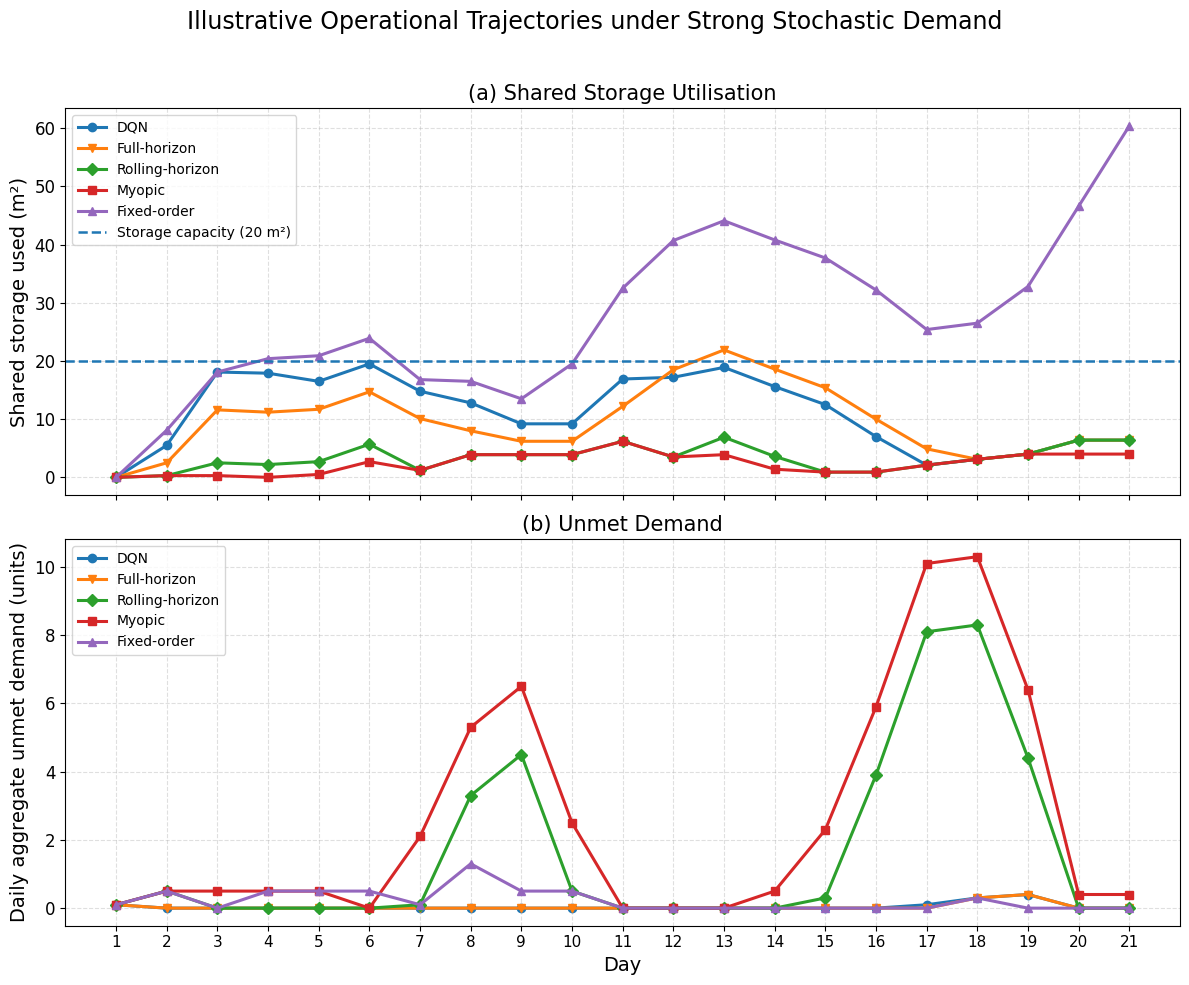

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# Illustrative matched strong-stochastic scenario
# EP12000, common stochastic realisation across policies
# ---------------------------------------------------

days = np.arange(1, 22)

# ---------------------------------------------------
# Shared storage used (m²)
# ---------------------------------------------------

dqn_storage = [
    0.0, 5.5, 18.1, 17.9, 16.5, 19.5, 14.8,
    12.8, 9.2, 9.2, 16.9, 17.2, 18.9, 15.6,
    12.5, 7.0, 2.1, 3.1, 4.0, 6.4, 6.4
]

full_horizon_storage = [
    0.0, 2.5, 11.6, 11.2, 11.7, 14.7, 10.1,
    8.0, 6.2, 6.2, 12.2, 18.5, 21.9, 18.6,
    15.4, 10.0, 4.9, 3.1, 4.0, 6.4, 6.4
]

rolling_storage = [
    0.0, 0.3, 2.5, 2.2, 2.7, 5.7, 1.2,
    3.9, 3.9, 3.9, 6.2, 3.5, 6.9, 3.6,
    0.9, 0.9, 2.1, 3.1, 4.0, 6.4, 6.4
]

myopic_storage = [
    0.0, 0.3, 0.3, 0.0, 0.5, 2.7, 1.2,
    3.9, 3.9, 3.9, 6.2, 3.5, 3.9, 1.4,
    0.9, 0.9, 2.1, 3.1, 4.0, 4.0, 4.0
]

fixed_storage = [
    0.0, 8.1, 18.1, 20.4, 20.9, 23.9, 16.8,
    16.5, 13.5, 19.5, 32.5, 40.7, 44.1, 40.8,
    37.7, 32.2, 25.4, 26.5, 32.8, 46.6, 60.4
]

# ---------------------------------------------------
# Daily aggregate unmet demand
# Sum of unmet A + B + C for each day
# ---------------------------------------------------

dqn_unmet = [
    0.1, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.1, 0.3, 0.4, 0.0, 0.0
]

full_horizon_unmet = [
    0.1, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.0, 0.3, 0.4, 0.0, 0.0
]

rolling_unmet = [
    0.1, 0.5, 0.0, 0.0, 0.0, 0.0, 0.1,
    3.3, 4.5, 0.5, 0.0, 0.0, 0.0, 0.0,
    0.3, 3.9, 8.1, 8.3, 4.4, 0.0, 0.0
]

myopic_unmet = [
    0.1, 0.5, 0.5, 0.5, 0.5, 0.0, 2.1,
    5.3, 6.5, 2.5, 0.0, 0.0, 0.0, 0.5,
    2.3, 5.9, 10.1, 10.3, 6.4, 0.4, 0.4
]

fixed_unmet = [
    0.1, 0.5, 0.0, 0.5, 0.5, 0.5, 0.1,
    1.3, 0.5, 0.5, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.0, 0.3, 0.0, 0.0, 0.0
]

storage_capacity = 20.0

# ---------------------------------------------------
# Figure
# ---------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 10),
    sharex=True
)

# ===================================================
# Panel (a): Shared storage utilisation
# ===================================================

axes[0].plot(
    days,
    dqn_storage,
    marker="o",
    linewidth=2.2,
    label="DQN"
)

axes[0].plot(
    days,
    full_horizon_storage,
    marker="v",
    linewidth=2.2,
    label="Full-horizon"
)

axes[0].plot(
    days,
    rolling_storage,
    marker="D",
    linewidth=2.2,
    label="Rolling-horizon"
)

axes[0].plot(
    days,
    myopic_storage,
    marker="s",
    linewidth=2.2,
    label="Myopic"
)

axes[0].plot(
    days,
    fixed_storage,
    marker="^",
    linewidth=2.2,
    label="Fixed-order"
)

axes[0].axhline(
    y=storage_capacity,
    linestyle="--",
    linewidth=1.8,
    label="Storage capacity (20 m²)"
)

axes[0].set_ylabel(
    "Shared storage used (m²)",
    fontsize=14
)

axes[0].set_title(
    "(a) Shared Storage Utilisation",
    fontsize=15
)

axes[0].tick_params(
    axis="y",
    labelsize=12
)

axes[0].grid(
    True,
    linestyle="--",
    alpha=0.4
)

axes[0].legend(
    fontsize=10,
    loc="upper left"
)

# ===================================================
# Panel (b): Daily aggregate unmet demand
# ===================================================

axes[1].plot(
    days,
    dqn_unmet,
    marker="o",
    linewidth=2.2,
    label="DQN"
)

axes[1].plot(
    days,
    full_horizon_unmet,
    marker="v",
    linewidth=2.2,
    label="Full-horizon"
)

axes[1].plot(
    days,
    rolling_unmet,
    marker="D",
    linewidth=2.2,
    label="Rolling-horizon"
)

axes[1].plot(
    days,
    myopic_unmet,
    marker="s",
    linewidth=2.2,
    label="Myopic"
)

axes[1].plot(
    days,
    fixed_unmet,
    marker="^",
    linewidth=2.2,
    label="Fixed-order"
)

axes[1].set_xlabel(
    "Day",
    fontsize=14
)

axes[1].set_ylabel(
    "Daily aggregate unmet demand (units)",
    fontsize=14
)

axes[1].set_title(
    "(b) Unmet Demand",
    fontsize=15
)

axes[1].set_xticks(days)

axes[1].tick_params(
    axis="x",
    labelsize=11
)

axes[1].tick_params(
    axis="y",
    labelsize=12
)

axes[1].grid(
    True,
    linestyle="--",
    alpha=0.4
)

axes[1].legend(
    fontsize=10,
    loc="upper left"
)

# ---------------------------------------------------
# Overall title and layout
# ---------------------------------------------------

fig.suptitle(
    "Illustrative Operational Trajectories under "
    "Strong Stochastic Demand",
    fontsize=17,
    y=0.98
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

# ---------------------------------------------------
# Save
# ---------------------------------------------------

plt.savefig(
    "illustrative_operational_behaviour_EP12000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "illustrative_operational_behaviour_EP12000.pdf",
    bbox_inches="tight"
)

plt.show()

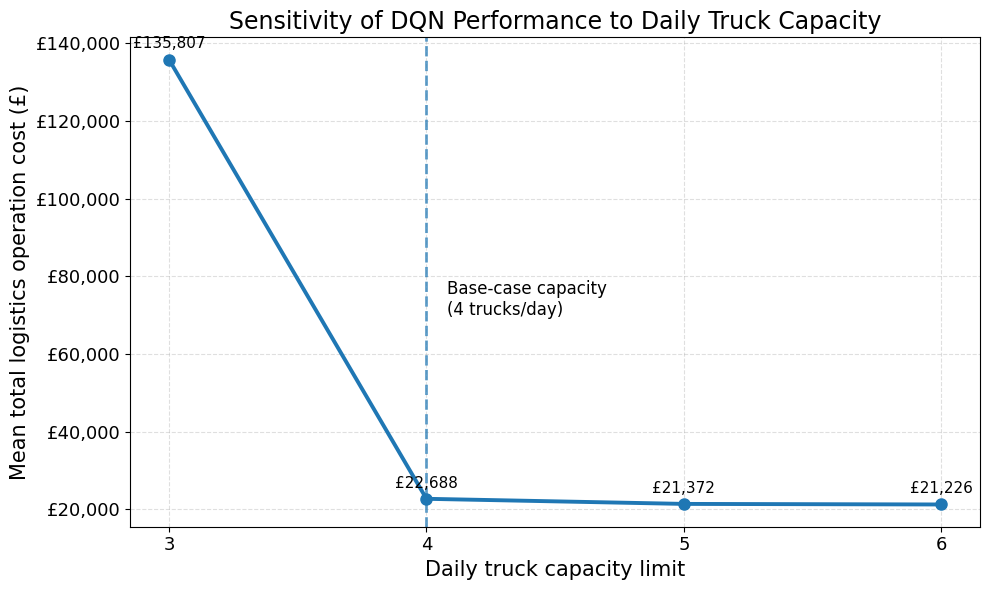

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Daily truck capacity sensitivity
truck_caps = np.array([3, 4, 5, 6])

# Mean total cost from 100 uncertain validation scenarios
mean_cost = np.array([
    135807.1390,
    22687.7255,
    21372.4320,
    21225.9610,
])

plt.figure(figsize=(10, 6))
ax = plt.gca()

plt.plot(
    truck_caps,
    mean_cost,
    marker="o",
    linewidth=2.8,
    markersize=8
)

# Base-case capacity
plt.axvline(
    x=4,
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

plt.text(
    4.08,
    70000,
    "Base-case capacity\n(4 trucks/day)",
    fontsize=12
)

# Value labels
for x, y in zip(truck_caps, mean_cost):
    ax.annotate(
        f"£{y:,.0f}",
        xy=(x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=11
    )

ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("£{x:,.0f}")
)

plt.xticks(truck_caps, fontsize=13)
plt.yticks(fontsize=13)

plt.xlabel(
    "Daily truck capacity limit",
    fontsize=15
)

plt.ylabel(
    "Mean total logistics operation cost (£)",
    fontsize=15
)

plt.title(
    "Sensitivity of DQN Performance to Daily Truck Capacity",
    fontsize=17
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "structural_truck_capacity_sensitivity_100scenarios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "structural_truck_capacity_sensitivity_100scenarios.pdf",
    bbox_inches="tight"
)

plt.show()

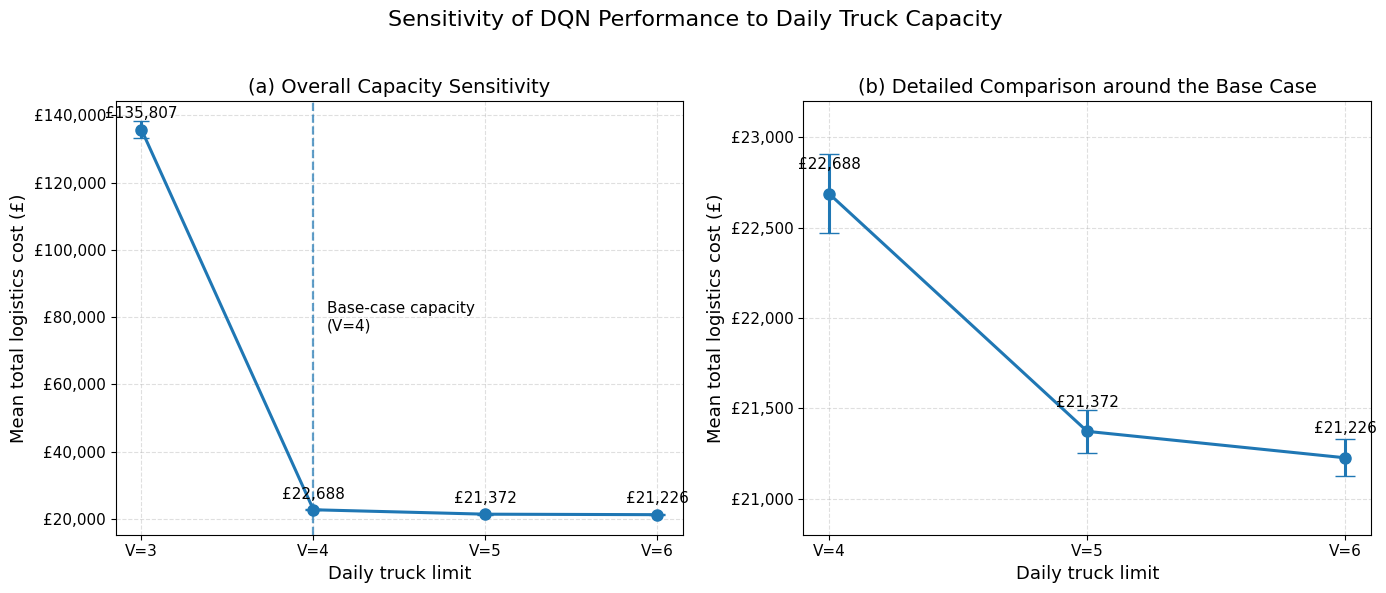

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ---------------------------------------------------
# DQN vehicle-capacity sensitivity results
# 100 stochastic scenarios per vehicle limit
# ---------------------------------------------------

vehicle_limits = np.array([3, 4, 5, 6])

mean_cost = np.array([
    135807.1390,
    22687.7255,
    21372.4320,
    21225.9610
])

ci_lower = np.array([
    133263.925784,
    22469.388274,
    21255.177657,
    21122.443630
])

ci_upper = np.array([
    138350.352216,
    22906.062700,
    21489.686343,
    21329.478370
])

# Convert CI bounds into error distances
lower_error = mean_cost - ci_lower
upper_error = ci_upper - mean_cost

yerr = np.vstack([
    lower_error,
    upper_error
])

# ---------------------------------------------------
# Two-panel figure
# ---------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

# ===================================================
# Panel (a): Full sensitivity range
# ===================================================

axes[0].errorbar(
    vehicle_limits,
    mean_cost,
    yerr=yerr,
    marker="o",
    markersize=8,
    linewidth=2.2,
    capsize=6
)

# Mark base case
axes[0].axvline(
    x=4,
    linestyle="--",
    linewidth=1.6,
    alpha=0.7
)

axes[0].text(
    4.08,
    76000,
    "Base-case capacity\n(V=4)",
    fontsize=11
)

# Value labels
for x, y in zip(vehicle_limits, mean_cost):
    axes[0].text(
        x,
        y + max(mean_cost) * 0.018,
        f"£{y:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

axes[0].set_xticks(vehicle_limits)
axes[0].set_xticklabels(
    [f"V={v}" for v in vehicle_limits],
    fontsize=11
)

axes[0].yaxis.set_major_formatter(
    mticker.StrMethodFormatter("£{x:,.0f}")
)

axes[0].set_xlabel(
    "Daily truck limit",
    fontsize=13
)

axes[0].set_ylabel(
    "Mean total logistics cost (£)",
    fontsize=13
)

axes[0].set_title(
    "(a) Overall Capacity Sensitivity",
    fontsize=14
)

axes[0].grid(
    True,
    linestyle="--",
    alpha=0.4
)

axes[0].tick_params(
    axis="y",
    labelsize=11
)

# ===================================================
# Panel (b): Zoomed V=4–6 comparison
# ===================================================

axes[1].errorbar(
    vehicle_limits[1:],
    mean_cost[1:],
    yerr=yerr[:, 1:],
    marker="o",
    markersize=8,
    linewidth=2.2,
    capsize=7
)

for x, y in zip(
    vehicle_limits[1:],
    mean_cost[1:]
):
    axes[1].text(
        x,
        y + 120,
        f"£{y:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

axes[1].set_xticks([4, 5, 6])
axes[1].set_xticklabels(
    ["V=4", "V=5", "V=6"],
    fontsize=11
)

axes[1].set_ylim(
    20800,
    23200
)

axes[1].yaxis.set_major_formatter(
    mticker.StrMethodFormatter("£{x:,.0f}")
)

axes[1].set_xlabel(
    "Daily truck limit",
    fontsize=13
)

axes[1].set_ylabel(
    "Mean total logistics cost (£)",
    fontsize=13
)

axes[1].set_title(
    "(b) Detailed Comparison around the Base Case",
    fontsize=14
)

axes[1].grid(
    True,
    linestyle="--",
    alpha=0.4
)

axes[1].tick_params(
    axis="y",
    labelsize=11
)

# ---------------------------------------------------
# Overall title and layout
# ---------------------------------------------------

fig.suptitle(
    "Sensitivity of DQN Performance to Daily Truck Capacity",
    fontsize=16,
    y=0.98
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

# ---------------------------------------------------
# Save
# ---------------------------------------------------

plt.savefig(
    "DQN_vehicle_capacity_sensitivity_two_panel_95CI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "DQN_vehicle_capacity_sensitivity_two_panel_95CI.pdf",
    bbox_inches="tight"
)

plt.show()